## Module 01: Research Configuration

In [1]:
# Cell 01: Import Standard Libraries

import json
from pathlib import Path
from urllib.parse import urlparse

In [2]:
# Cell 02: Define Basic Validation Functions

SUPPORTED_METRICS = ["sales_growth", "operating_margin", "sales_index"]


def check_text(value, field_name):
    """Check that a setting contains non-empty text."""
    if not isinstance(value, str) or not value.strip():
        raise ValueError(f"{field_name} must be a non-empty string.")


def check_year(value, field_name):
    """Check that a setting contains a reasonable integer year."""
    if type(value) is not int:
        raise ValueError(f"{field_name} must be an integer.")
    if value < 1900 or value > 2100:
        raise ValueError(f"{field_name} must be between 1900 and 2100.")

In [3]:
# Cell 03: Define the Study Configuration Class

class StudyConfig:
    """Store and validate one study without collecting financial data."""

    def __init__(self, settings):
        if not isinstance(settings, dict):
            raise ValueError("Study settings must be a dictionary.")

        required_fields = [
            "study_id", "title", "research_question", "frequency", "currency",
            "business_units", "periods", "metrics", "index_base_year",
            "missing_previous_period", "alignment_note", "data_file",
            "results_directory",
        ]
        for field_name in required_fields:
            if field_name not in settings:
                raise ValueError(f"Missing study setting: {field_name}")

        self.study_id = settings["study_id"]
        self.title = settings["title"]
        self.research_question = settings["research_question"]
        self.frequency = settings["frequency"]
        self.currency = settings["currency"]
        self.business_units = settings["business_units"]
        self.periods = settings["periods"]
        self.metrics = settings["metrics"]
        self.index_base_year = settings["index_base_year"]
        self.missing_previous_period = settings["missing_previous_period"]
        self.alignment_note = settings["alignment_note"]
        self.data_file = settings["data_file"]
        self.results_directory = settings["results_directory"]
        self.database_file = settings.get("database_file", "../data/retail_comparison.sqlite")
        self.validate()

    def validate(self):
        """Check content before later modules use the configuration."""
        values = self.to_dict()
        text_fields = [
            "study_id", "title", "research_question", "currency",
            "alignment_note", "data_file", "results_directory", "database_file",
        ]
        for field_name in text_fields:
            check_text(values[field_name], field_name)

        if self.frequency != "annual":
            raise ValueError("Only annual studies are supported.")
        if len(self.currency) != 3 or not self.currency.isalpha() or not self.currency.isupper():
            raise ValueError("Currency must be a three-letter uppercase code.")
        if not isinstance(self.business_units, list) or len(self.business_units) < 2:
            raise ValueError("A comparison requires at least two business units.")

        unit_ids = []
        for unit in self.business_units:
            if not isinstance(unit, dict):
                raise ValueError("Each business unit must be a dictionary.")
            for field_name in ["unit_id", "company_name", "ticker", "segment_name", "currency"]:
                check_text(unit.get(field_name), field_name)
            if unit["unit_id"] in unit_ids:
                raise ValueError("Business unit IDs must be unique.")
            unit_ids.append(unit["unit_id"])
            if unit["currency"] != self.currency:
                raise ValueError("All business units must use the study currency.")

            sources = unit.get("source_urls")
            if not isinstance(sources, list) or len(sources) == 0:
                raise ValueError("Each business unit needs a list of source URLs.")
            for url in sources:
                check_text(url, "source_url")
                parsed_url = urlparse(url)
                if parsed_url.scheme not in ["http", "https"] or not parsed_url.netloc:
                    raise ValueError(f"Invalid source URL: {url}")

            notes = unit.get("scope_notes")
            if not isinstance(notes, list) or len(notes) == 0:
                raise ValueError("Each business unit needs a list of scope notes.")
            for note in notes:
                check_text(note, "scope_note")

        if not isinstance(self.periods, list) or len(self.periods) < 2:
            raise ValueError("A trend comparison requires at least two annual periods.")

        analysis_years = []
        previous_fiscal_years = {}
        for period in self.periods:
            if not isinstance(period, dict):
                raise ValueError("Each period must be a dictionary.")
            year = period.get("analysis_year")
            check_year(year, "analysis_year")
            if len(analysis_years) > 0 and year != analysis_years[-1] + 1:
                raise ValueError("Analysis years must be consecutive and ordered.")
            analysis_years.append(year)

            fiscal_years = period.get("fiscal_years")
            if not isinstance(fiscal_years, dict):
                raise ValueError("Fiscal years must be a dictionary.")
            if set(fiscal_years.keys()) != set(unit_ids):
                raise ValueError("Each period must map exactly the configured business units.")
            for unit_id in unit_ids:
                fiscal_year = fiscal_years[unit_id]
                check_year(fiscal_year, "fiscal_year")
                if unit_id in previous_fiscal_years:
                    if fiscal_year != previous_fiscal_years[unit_id] + 1:
                        raise ValueError("Each unit's fiscal years must be consecutive and ordered.")
                previous_fiscal_years[unit_id] = fiscal_year

        if not isinstance(self.metrics, list) or len(self.metrics) == 0:
            raise ValueError("Metrics must be a non-empty list.")
        used_metrics = []
        for metric in self.metrics:
            if metric not in SUPPORTED_METRICS:
                raise ValueError("Supported metrics: sales_growth, operating_margin, sales_index.")
            if metric in used_metrics:
                raise ValueError("Metric IDs must be unique.")
            used_metrics.append(metric)

        check_year(self.index_base_year, "index_base_year")
        if self.index_base_year not in analysis_years:
            raise ValueError("The index base year must be an analysis year.")
        if self.missing_previous_period != "leave_missing":
            raise ValueError("Missing growth must be left missing, not replaced with zero.")

        for file_path in [self.data_file, self.database_file, self.results_directory]:
            if Path(file_path).is_absolute():
                raise ValueError("Data, database, and result paths must be relative to the configuration file.")
        if Path(self.database_file).suffix.lower() not in [".sqlite", ".sqlite3", ".db"]:
            raise ValueError("Database files must use .sqlite, .sqlite3, or .db.")
        if Path(self.data_file) == Path(self.database_file):
            raise ValueError("The import file and database must have different paths.")

    def get_observation_count(self):
        """Return the planned number of segment-year observations."""
        return len(self.business_units) * len(self.periods)

    def resolve_paths(self, config_path):
        """Resolve paths without creating files or a database."""
        base_folder = Path(config_path).resolve().parent
        return {
            "data_file": (base_folder / self.data_file).resolve(),
            "database_file": (base_folder / self.database_file).resolve(),
            "results_directory": (base_folder / self.results_directory).resolve(),
        }

    def to_dict(self):
        """Prepare configuration content for JSON storage."""
        return {
            "study_id": self.study_id,
            "title": self.title,
            "research_question": self.research_question,
            "frequency": self.frequency,
            "currency": self.currency,
            "business_units": self.business_units,
            "periods": self.periods,
            "metrics": self.metrics,
            "index_base_year": self.index_base_year,
            "missing_previous_period": self.missing_previous_period,
            "alignment_note": self.alignment_note,
            "data_file": self.data_file,
            "results_directory": self.results_directory,
            "database_file": self.database_file,
        }

In [4]:
# Cell 04: Define Configuration File Functions

def save_study_config(config, file_path):
    """Save settings only; do not create a financial database."""
    config.validate()
    with open(file_path, "w", encoding="utf-8") as file:
        json.dump(config.to_dict(), file, indent=2, ensure_ascii=True)
        file.write("\n")


def load_study_config(file_path):
    """Load a JSON file and construct a validated study object."""
    with open(file_path, "r", encoding="utf-8") as file:
        settings = json.load(file)
    return StudyConfig(settings)

In [5]:
# Cell 05: Set the Research Content

study_settings = {'study_id': 'amazon_walmart_segment_comparison',
 'title': 'Sales Growth and Operating Profitability of Internet-Origin and Store-Origin Retailers: '
          'Amazon North America and Walmart U.S. Around the COVID-19 Pandemic, 2019-2024',
 'research_question': 'Relative to a 2019 pre-pandemic baseline, how did sales growth and '
                      'operating margins differ between Amazon North America and Walmart U.S. '
                      'during 2020-2021 and the subsequent 2022-2024 adjustment period? This is a '
                      'descriptive comparison, not an estimate of the causal effect of COVID-19.',
 'frequency': 'annual',
 'currency': 'USD',
 'business_units': [{'unit_id': 'amazon_north_america',
                     'company_name': 'Amazon.com, Inc.',
                     'ticker': 'AMZN',
                     'segment_name': 'North America',
                     'currency': 'USD',
                     'source_urls': ['https://ir.aboutamazon.com/annual-reports-proxies-and-shareholder-letters/default.aspx',
                                     'https://www.sec.gov/Archives/edgar/data/1018724/000101872422000005/amzn-20211231.htm',
                                     'https://www.sec.gov/Archives/edgar/data/1018724/000101872425000004/amzn-20241231.htm'],
                     'scope_notes': ['Use North America segment net sales and operating income, '
                                     'not consolidated totals.',
                                     'The segment excludes AWS but includes advertising, '
                                     'subscription services, and third-party seller services.',
                                     "The segment's geographical scope and revenue recognition "
                                     'differ from Walmart U.S.']},
                    {'unit_id': 'walmart_us',
                     'company_name': 'Walmart Inc.',
                     'ticker': 'WMT',
                     'segment_name': 'Walmart U.S.',
                     'currency': 'USD',
                     'source_urls': ['https://stock.walmart.com/financial-information/annual-reports',
                                     'https://www.sec.gov/Archives/edgar/data/104169/000010416922000012/wmt-20220131.htm',
                                     'https://stock.walmart.com/sec-filings/all-sec-filings/content/0000104169-25-000021/wmt-20250131.htm/wmtexhibit991fy2510-k.htm'],
                     'scope_notes': ['Use Walmart U.S. segment net sales and operating income, not '
                                     'consolidated totals.',
                                     "Exclude Sam's Club and Walmart International from the "
                                     'selected segment data.',
                                     'Walmart fiscal years end on January 31 of the labeled '
                                     'year.']}],
 'periods': [{'analysis_year': 2019,
              'fiscal_years': {'amazon_north_america': 2019, 'walmart_us': 2020},
              'comparison_stage': 'Pre-pandemic baseline'},
             {'analysis_year': 2020,
              'fiscal_years': {'amazon_north_america': 2020, 'walmart_us': 2021},
              'comparison_stage': 'Pandemic disruption'},
             {'analysis_year': 2021,
              'fiscal_years': {'amazon_north_america': 2021, 'walmart_us': 2022},
              'comparison_stage': 'Pandemic disruption'},
             {'analysis_year': 2022,
              'fiscal_years': {'amazon_north_america': 2022, 'walmart_us': 2023},
              'comparison_stage': 'Subsequent adjustment'},
             {'analysis_year': 2023,
              'fiscal_years': {'amazon_north_america': 2023, 'walmart_us': 2024},
              'comparison_stage': 'Subsequent adjustment'},
             {'analysis_year': 2024,
              'fiscal_years': {'amazon_north_america': 2024, 'walmart_us': 2025},
              'comparison_stage': 'Subsequent adjustment'}],
 'metrics': ['sales_growth', 'operating_margin', 'sales_index'],
 'index_base_year': 2019,
 'missing_previous_period': 'leave_missing',
 'alignment_note': 'Amazon years ending December 31 are paired with Walmart fiscal years ending '
                   'January 31 of the following year. These are approximately corresponding '
                   'periods, not identical periods. Actual start and end dates must be recorded '
                   'and checked in the data module.',
 'data_file': 'data/financial_data.csv',
 'results_directory': 'results',
 'database_file': 'data/retail_comparison.sqlite'}

In [6]:
# Cell 06: Create and Validate the Configuration Object

config = StudyConfig(study_settings)
print("Configuration is valid.")

Configuration is valid.


In [7]:
# Cell 07: Review the Study Scope and Fiscal Mapping

print(f"Study: {config.title}")
print(f"Research question: {config.research_question}")
print(f"Currency: {config.currency}")
print(f"Business units: {len(config.business_units)}")
print(f"Planned observations: {config.get_observation_count()}")
print(f"Metrics: {', '.join(config.metrics)}")
print(f"Index base year: {config.index_base_year}")

print("\nBusiness unit scope:")
for unit in config.business_units:
    print(f"{unit['company_name']} / {unit['segment_name']}")
    for note in unit["scope_notes"]:
        print(f"  - {note}")

print("\nFiscal period mapping:")
for period in config.periods:
    print(f"Analysis year: {period['analysis_year']}")
    print(f"  Comparison stage: {period.get('comparison_stage', 'Not specified')}")
    for unit in config.business_units:
        unit_id = unit["unit_id"]
        fiscal_year = period["fiscal_years"][unit_id]
        print(f"  {unit['company_name']}: FY{fiscal_year}")

print(f"\nAlignment note: {config.alignment_note}")
print("Financial data has not been loaded or calculated.")

Study: Sales Growth and Operating Profitability of Internet-Origin and Store-Origin Retailers: Amazon North America and Walmart U.S. Around the COVID-19 Pandemic, 2019-2024
Research question: Relative to a 2019 pre-pandemic baseline, how did sales growth and operating margins differ between Amazon North America and Walmart U.S. during 2020-2021 and the subsequent 2022-2024 adjustment period? This is a descriptive comparison, not an estimate of the causal effect of COVID-19.
Currency: USD
Business units: 2
Planned observations: 12
Metrics: sales_growth, operating_margin, sales_index
Index base year: 2019

Business unit scope:
Amazon.com, Inc. / North America
  - Use North America segment net sales and operating income, not consolidated totals.
  - The segment excludes AWS but includes advertising, subscription services, and third-party seller services.
  - The segment's geographical scope and revenue recognition differ from Walmart U.S.
Walmart Inc. / Walmart U.S.
  - Use Walmart U.S. s

In [8]:
# Cell 08: Save and Reload the Configuration

CONFIG_PATH = Path.cwd() / "study.json"
print(f"Config file: {CONFIG_PATH.resolve()}")

save_study_config(config, CONFIG_PATH)
reloaded_config = load_study_config(CONFIG_PATH)

if reloaded_config.to_dict() != config.to_dict():
    raise ValueError("The saved configuration does not match the original.")

paths = reloaded_config.resolve_paths(CONFIG_PATH)
print("Configuration saved and reloaded successfully.")
print(f"Import file: {paths['data_file']}")
print(f"Database file: {paths['database_file']}")
print(f"Results directory: {paths['results_directory']}")
print("No financial data file, database, or results directory was created.")

Config file: /Users/dadabaibaidegoose/Documents/Codex/2026-10-10/shanc/outputs/Retail_Growth_and_Profitability_Comparison/study.json
Configuration saved and reloaded successfully.
Import file: /Users/dadabaibaidegoose/Documents/Codex/2026-10-10/shanc/outputs/Retail_Growth_and_Profitability_Comparison/data/financial_data.csv
Database file: /Users/dadabaibaidegoose/Documents/Codex/2026-10-10/shanc/outputs/Retail_Growth_and_Profitability_Comparison/data/retail_comparison.sqlite
Results directory: /Users/dadabaibaidegoose/Documents/Codex/2026-10-10/shanc/outputs/Retail_Growth_and_Profitability_Comparison/results
No financial data file, database, or results directory was created.


## Module 02: Data and Database Management

In [9]:
# Cell 01: Import Libraries

import math
import re
import sqlite3
from pathlib import Path
from urllib.parse import urlparse

import pandas as pd
import sys

In [10]:
# Cell 02: Load Study Configuration and Set Input Paths

CONFIG_PATH = Path.cwd() / "study.json"

config = load_study_config(CONFIG_PATH)
paths = config.resolve_paths(CONFIG_PATH)
DATA_FILE = paths["data_file"]
DATABASE_FILE = paths["database_file"]
RAW_DIRECTORY = DATA_FILE.parent / "raw"
CLEAN_FILE = DATA_FILE.parent / "clean" / "financial_records.csv"

RAW_FILES = {
    "amazon_north_america": RAW_DIRECTORY / "amazon_segment_raw.csv",
    "walmart_us": RAW_DIRECTORY / "walmart_segment_raw.csv",
}

print(f"Working directory: {Path.cwd()}")
print(f"Configuration: {CONFIG_PATH}")
print(f"Planned records: {config.get_observation_count()}")
print(f"Index base year: {config.index_base_year}")
print(f"Database: {DATABASE_FILE}")

Working directory: /Users/dadabaibaidegoose/Documents/Codex/2026-10-10/shanc/outputs/Retail_Growth_and_Profitability_Comparison
Configuration: /Users/dadabaibaidegoose/Documents/Codex/2026-10-10/shanc/outputs/Retail_Growth_and_Profitability_Comparison/study.json
Planned records: 12
Index base year: 2019
Database: /Users/dadabaibaidegoose/Documents/Codex/2026-10-10/shanc/outputs/Retail_Growth_and_Profitability_Comparison/data/retail_comparison.sqlite


In [11]:
# Cell 03: Define Cleaning Functions

RAW_COLUMNS = [
    "unit_id", "company_name", "segment_name", "fiscal_year",
    "period_start", "period_end", "net_sales_raw", "operating_income_raw",
    "reported_currency", "reported_unit", "source_url", "source_section",
    "accessed_date", "date_basis",
]

UNIT_MULTIPLIERS = {"units": 0.000001, "millions": 1.0, "billions": 1000.0}

RECORD_COLUMNS = [
    "unit_id", "fiscal_year", "period_start", "period_end",
    "net_sales_raw", "operating_income_raw", "reported_currency",
    "reported_unit", "source_url", "source_section", "accessed_date",
    "date_basis", "net_sales_usd_m", "operating_income_usd_m",
]


def parse_amount(value):
    """Convert a reported amount string without treating missing data as zero."""
    text = str(value).strip().replace(",", "")
    if text.startswith("(") and text.endswith(")"):
        text = "-" + text[1:-1]
    if re.fullmatch(r"-?\d+(\.\d+)?", text) is None:
        raise ValueError(f"Invalid reported amount: {value}")
    amount = float(pd.to_numeric(text, errors="raise"))
    if not math.isfinite(amount):
        raise ValueError(f"Reported amount must be finite: {value}")
    return amount


def standardize_records(raw_df):
    """Preserve source strings and add numeric amounts in USD millions."""
    for column in RAW_COLUMNS:
        if column not in raw_df.columns:
            raise ValueError(f"Missing raw column: {column}")

    clean_df = raw_df[RAW_COLUMNS].copy()
    for column in RAW_COLUMNS:
        if clean_df[column].isna().any():
            raise ValueError(f"Missing value in column: {column}")
        clean_df[column] = clean_df[column].astype(str).str.strip()
        if clean_df[column].eq("").any():
            raise ValueError(f"Blank value in column: {column}")

    years = pd.to_numeric(clean_df["fiscal_year"], errors="raise")
    if not years.between(1900, 2100).all() or not years.eq(years.round()).all():
        raise ValueError("Fiscal years must be integer years between 1900 and 2100.")
    clean_df["fiscal_year"] = years.astype(int)

    for column in ["period_start", "period_end", "accessed_date"]:
        dates = pd.to_datetime(clean_df[column], format="%Y-%m-%d", errors="raise")
        clean_df[column] = dates.dt.strftime("%Y-%m-%d")

    sales_values = []
    income_values = []
    for row in clean_df.to_dict("records"):
        if row["reported_currency"] != "USD":
            raise ValueError("This version supports USD records only; it does not convert currencies.")
        if row["reported_unit"] not in UNIT_MULTIPLIERS:
            raise ValueError(f"Unsupported reported unit: {row['reported_unit']}")
        multiplier = UNIT_MULTIPLIERS[row["reported_unit"]]
        sales_values.append(parse_amount(row["net_sales_raw"]) * multiplier)
        income_values.append(parse_amount(row["operating_income_raw"]) * multiplier)

    clean_df["net_sales_usd_m"] = sales_values
    clean_df["operating_income_usd_m"] = income_values
    return clean_df.sort_values(["unit_id", "fiscal_year"]).reset_index(drop=True)

In [12]:
# Cell 04: Define Record Validation

def validate_records(clean_df, config):
    """Require exact configured coverage, correct identities and usable values."""
    if config.currency != "USD":
        raise ValueError("The configuration must use USD for this version.")
    if clean_df.duplicated(["unit_id", "fiscal_year"]).any():
        raise ValueError("Duplicate segment/fiscal-year records were found.")

    expected_keys = set()
    units_by_id = {}
    for unit in config.business_units:
        units_by_id[unit["unit_id"]] = unit
    for period in config.periods:
        for unit_id in units_by_id:
            expected_keys.add((unit_id, period["fiscal_years"][unit_id]))

    actual_keys = set()
    for row in clean_df.to_dict("records"):
        key = (row["unit_id"], row["fiscal_year"])
        actual_keys.add(key)
        if row["unit_id"] not in units_by_id:
            raise ValueError(f"Unexpected business unit: {row['unit_id']}")
        unit = units_by_id[row["unit_id"]]
        if row["company_name"] != unit["company_name"] or row["segment_name"] != unit["segment_name"]:
            raise ValueError(f"Company or segment name does not match configuration: {key}")
        if row["reported_currency"] != config.currency:
            raise ValueError(f"Currency does not match configuration: {key}")
        if row["period_start"] >= row["period_end"]:
            raise ValueError(f"Report start must be before report end: {key}")
        for column in ["net_sales_usd_m", "operating_income_usd_m"]:
            if not math.isfinite(float(row[column])):
                raise ValueError(f"Non-finite financial value in {column}: {key}")
        if row["net_sales_usd_m"] <= 0:
            raise ValueError(f"Net sales must be positive: {key}")
        source = urlparse(row["source_url"])
        if source.scheme not in ["http", "https"] or not source.netloc:
            raise ValueError(f"Invalid source URL: {key}")
        for column in ["source_section", "date_basis", "accessed_date"]:
            if not str(row[column]).strip():
                raise ValueError(f"Missing provenance in {column}: {key}")

    if actual_keys != expected_keys:
        missing = sorted(expected_keys - actual_keys)
        extra = sorted(actual_keys - expected_keys)
        raise ValueError(f"Coverage mismatch. Missing: {missing}; extra: {extra}")
    if len(clean_df) != config.get_observation_count():
        raise ValueError("Record count does not match the configured study.")

In [13]:
# Cell 05: Define the Database Manager

class DatabaseManager:
    """Own the database connection without embedding company-specific rules."""

    def __init__(self, database_path):
        self.database_path = Path(database_path)
        self.connection = None

    def connect(self):
        if self.connection is None:
            self.database_path.parent.mkdir(parents=True, exist_ok=True)
            self.connection = sqlite3.connect(str(self.database_path))
            self.connection.execute("PRAGMA foreign_keys = ON")

    def create_tables(self):
        self.connection.executescript("""
            CREATE TABLE IF NOT EXISTS business_units (
                unit_id TEXT PRIMARY KEY,
                company_name TEXT NOT NULL,
                ticker TEXT NOT NULL,
                segment_name TEXT NOT NULL,
                currency TEXT NOT NULL,
                scope_notes TEXT NOT NULL,
                source_urls TEXT NOT NULL
            );
            CREATE TABLE IF NOT EXISTS financial_records (
                unit_id TEXT NOT NULL,
                fiscal_year INTEGER NOT NULL,
                period_start TEXT NOT NULL,
                period_end TEXT NOT NULL,
                net_sales_raw TEXT NOT NULL,
                operating_income_raw TEXT NOT NULL,
                reported_currency TEXT NOT NULL CHECK (reported_currency = 'USD'),
                reported_unit TEXT NOT NULL,
                source_url TEXT NOT NULL,
                source_section TEXT NOT NULL,
                accessed_date TEXT NOT NULL,
                date_basis TEXT NOT NULL,
                net_sales_usd_m REAL NOT NULL CHECK (net_sales_usd_m > 0),
                operating_income_usd_m REAL NOT NULL,
                PRIMARY KEY (unit_id, fiscal_year),
                FOREIGN KEY (unit_id) REFERENCES business_units(unit_id),
                CHECK (period_start < period_end)
            );
            CREATE TABLE IF NOT EXISTS metric_results (
                study_id TEXT NOT NULL,
                config_signature TEXT NOT NULL,
                unit_id TEXT NOT NULL,
                analysis_year INTEGER NOT NULL,
                metric_name TEXT NOT NULL,
                metric_value REAL,
                value_unit TEXT NOT NULL,
                calculation_time TEXT NOT NULL,
                missing_reason TEXT,
                PRIMARY KEY (study_id, config_signature, unit_id, analysis_year, metric_name),
                FOREIGN KEY (unit_id) REFERENCES business_units(unit_id)
            );
        """)

    def save_data(self, config, clean_df):
        counts = {"inserted": 0, "updated": 0, "unchanged": 0}
        columns_sql = ", ".join(RECORD_COLUMNS)
        placeholders = ", ".join(["?"] * len(RECORD_COLUMNS))
        update_parts = []
        for column in RECORD_COLUMNS[2:]:
            update_parts.append(column + " = ?")
        update_sql = ", ".join(update_parts)

        with self.connection:
            for unit in config.business_units:
                unit_values = (
                    unit["company_name"], unit["ticker"], unit["segment_name"],
                    unit["currency"], "\n".join(unit["scope_notes"]),
                    "\n".join(unit["source_urls"]),
                )
                existing_unit = self.connection.execute(
                    "SELECT company_name, ticker, segment_name, currency, scope_notes, source_urls "
                    "FROM business_units WHERE unit_id = ?", (unit["unit_id"],)
                ).fetchone()
                if existing_unit is None:
                    self.connection.execute(
                        "INSERT INTO business_units "
                        "(company_name, ticker, segment_name, currency, scope_notes, source_urls, unit_id) "
                        "VALUES (?, ?, ?, ?, ?, ?, ?)", unit_values + (unit["unit_id"],)
                    )
                elif existing_unit != unit_values:
                    self.connection.execute(
                        "UPDATE business_units SET company_name = ?, ticker = ?, segment_name = ?, "
                        "currency = ?, scope_notes = ?, source_urls = ? WHERE unit_id = ?",
                        unit_values + (unit["unit_id"],)
                    )
                    self.connection.execute("DELETE FROM metric_results WHERE unit_id = ?", (unit["unit_id"],))

            for row in clean_df.to_dict("records"):
                values = []
                for column in RECORD_COLUMNS:
                    values.append(row[column])
                values = tuple(values)
                key = (row["unit_id"], row["fiscal_year"])
                existing = self.connection.execute(
                    f"SELECT {columns_sql} FROM financial_records WHERE unit_id = ? AND fiscal_year = ?", key
                ).fetchone()
                if existing is None:
                    self.connection.execute(
                        f"INSERT INTO financial_records ({columns_sql}) VALUES ({placeholders})", values
                    )
                    counts["inserted"] += 1
                    self.connection.execute("DELETE FROM metric_results WHERE unit_id = ?", (row["unit_id"],))
                elif existing != values:
                    self.connection.execute(
                        f"UPDATE financial_records SET {update_sql} WHERE unit_id = ? AND fiscal_year = ?",
                        values[2:] + key,
                    )
                    counts["updated"] += 1
                    self.connection.execute("DELETE FROM metric_results WHERE unit_id = ?", (row["unit_id"],))
                else:
                    counts["unchanged"] += 1
        return counts

    def read_selected_records(self, config):
        frames = []
        for unit in config.business_units:
            years = []
            for period in config.periods:
                years.append(period["fiscal_years"][unit["unit_id"]])
            placeholders = ", ".join(["?"] * len(years))
            parameters = [unit["unit_id"]] + years
            query = f"""
                SELECT f.*, b.company_name, b.segment_name
                FROM financial_records AS f
                JOIN business_units AS b ON f.unit_id = b.unit_id
                WHERE f.unit_id = ? AND f.fiscal_year IN ({placeholders})
                ORDER BY f.fiscal_year
            """
            frames.append(pd.read_sql_query(query, self.connection, params=parameters))
        financial_df = pd.concat(frames, ignore_index=True)
        return financial_df.sort_values(["unit_id", "fiscal_year"]).reset_index(drop=True)

    def get_table_counts(self):
        counts = {}
        for table in ["business_units", "financial_records", "metric_results"]:
            row = self.connection.execute(f"SELECT COUNT(*) FROM {table}").fetchone()
            counts[table] = row[0]
        return counts

    def close(self):
        if self.connection is not None:
            self.connection.close()
            self.connection = None

In [14]:
# Cell 06: Load Source CSV Files into DataFrames

source_frames = {}
for unit_id in RAW_FILES:
    raw_file = RAW_FILES[unit_id]
    frame = pd.read_csv(raw_file, dtype=str, keep_default_na=False)
    if "unit_id" not in frame.columns or not frame["unit_id"].eq(unit_id).all():
        raise ValueError(f"Source file does not match its configured unit: {raw_file}")
    source_frames[unit_id] = frame
    print(f"Loaded {unit_id}: {len(frame)} rows")

amazon_raw_df = source_frames["amazon_north_america"]
walmart_raw_df = source_frames["walmart_us"]
raw_df = pd.concat(list(source_frames.values()), ignore_index=True)

print(f"Combined raw records: {len(raw_df)}")
print(raw_df[["unit_id", "fiscal_year", "net_sales_raw", "operating_income_raw"]].to_string(index=False))

Loaded amazon_north_america: 6 rows
Loaded walmart_us: 6 rows
Combined raw records: 12
             unit_id fiscal_year net_sales_raw operating_income_raw
amazon_north_america        2019       170,773                7,033
amazon_north_america        2020       236,282                8,651
amazon_north_america        2021       279,833                7,271
amazon_north_america        2022       315,880              (2,847)
amazon_north_america        2023       352,828               14,877
amazon_north_america        2024       387,497               24,967
          walmart_us        2020       341,004               17,380
          walmart_us        2021       369,963               19,116
          walmart_us        2022       393,247               21,587
          walmart_us        2023       420,553               20,620
          walmart_us        2024       441,817               22,154
          walmart_us        2025       462,415               23,882


In [15]:
# Cell 07: Standardize and Validate the Financial Records

clean_df = standardize_records(raw_df)
validate_records(clean_df, config)

print("Financial record checks passed.")
print(clean_df[["unit_id", "fiscal_year", "period_start", "period_end", "net_sales_usd_m", "operating_income_usd_m"]].to_string(index=False))

Financial record checks passed.
             unit_id  fiscal_year period_start period_end  net_sales_usd_m  operating_income_usd_m
amazon_north_america         2019   2019-01-01 2019-12-31         170773.0                  7033.0
amazon_north_america         2020   2020-01-01 2020-12-31         236282.0                  8651.0
amazon_north_america         2021   2021-01-01 2021-12-31         279833.0                  7271.0
amazon_north_america         2022   2022-01-01 2022-12-31         315880.0                 -2847.0
amazon_north_america         2023   2023-01-01 2023-12-31         352828.0                 14877.0
amazon_north_america         2024   2024-01-01 2024-12-31         387497.0                 24967.0
          walmart_us         2020   2019-02-01 2020-01-31         341004.0                 17380.0
          walmart_us         2021   2020-02-01 2021-01-31         369963.0                 19116.0
          walmart_us         2022   2021-02-01 2022-01-31         393247.0   

In [16]:
# Cell 08: Save the Import Snapshot and Clean Audit File

DATA_FILE.parent.mkdir(parents=True, exist_ok=True)
CLEAN_FILE.parent.mkdir(parents=True, exist_ok=True)
raw_df.to_csv(DATA_FILE, index=False)
clean_df.to_csv(CLEAN_FILE, index=False)

print(f"Import snapshot saved: {DATA_FILE}")
print(f"Clean audit file saved: {CLEAN_FILE}")

Import snapshot saved: /Users/dadabaibaidegoose/Documents/Codex/2026-10-10/shanc/outputs/Retail_Growth_and_Profitability_Comparison/data/financial_data.csv
Clean audit file saved: /Users/dadabaibaidegoose/Documents/Codex/2026-10-10/shanc/outputs/Retail_Growth_and_Profitability_Comparison/data/clean/financial_records.csv


In [17]:
# Cell 09: Connect to SQLite and Create Tables

database = DatabaseManager(DATABASE_FILE)
database.connect()
database.create_tables()
print("Database connected and tables are available.")

Database connected and tables are available.


In [18]:
# Cell 10: Write the Accepted Records in One Transaction

write_counts = database.save_data(config, clean_df)
print(f"Inserted records: {write_counts['inserted']}")
print(f"Updated records: {write_counts['updated']}")
print(f"Unchanged records: {write_counts['unchanged']}")

Inserted records: 0
Updated records: 0
Unchanged records: 12


In [19]:
# Cell 11: Read Back and Verify the Persisted Records

def verify_database_copy(clean_df, financial_df):
    """Compare every imported field after reading the persisted records back."""
    left = clean_df.sort_values(["unit_id", "fiscal_year"]).reset_index(drop=True)
    right = financial_df.sort_values(["unit_id", "fiscal_year"]).reset_index(drop=True)
    if len(left) != len(right):
        raise ValueError("Database row count does not match the accepted records.")
    for column in left.columns:
        if column not in right.columns or left[column].tolist() != right[column].tolist():
            raise ValueError(f"Database values differ from accepted records: {column}")

financial_df = database.read_selected_records(config)
validate_records(financial_df, config)
verify_database_copy(clean_df, financial_df)

table_counts = database.get_table_counts()
print("Database read-back verification passed.")
print(f"Selected financial records: {len(financial_df)}")
for table in table_counts:
    print(f"{table}: {table_counts[table]} rows")

Database read-back verification passed.
Selected financial records: 12
business_units: 2 rows
financial_records: 12 rows
metric_results: 36 rows


In [20]:
# Cell 12: Close the Connection and Prepare the Next Module

database.close()
print("Database connection closed.")
print("Module 02 completed.")
print(f"Persistent database: {DATABASE_FILE}")
print("Next: query financial_records, join study periods and calculate metrics.")
print("No sales growth, operating margin or sales index has been calculated in Module 02.")

Database connection closed.
Module 02 completed.
Persistent database: /Users/dadabaibaidegoose/Documents/Codex/2026-10-10/shanc/outputs/Retail_Growth_and_Profitability_Comparison/data/retail_comparison.sqlite
Next: query financial_records, join study periods and calculate metrics.
No sales growth, operating margin or sales index has been calculated in Module 02.


## Module 03: Metrics and Comparative Analysis

In [21]:
# Cell 01: Import Libraries

import hashlib
import json
import math
from datetime import datetime, timezone
from pathlib import Path

import pandas as pd

In [22]:
# Cell 02: Reload Configuration and Set Analysis Paths

CONFIG_PATH = Path.cwd() / "study.json"
if not CONFIG_PATH.is_file():
    raise FileNotFoundError("Run the combined notebook from the project root containing study.json.")
config = load_study_config(CONFIG_PATH)
paths = config.resolve_paths(CONFIG_PATH)
DATABASE_FILE = paths["database_file"]
RESULTS_DIRECTORY = paths["results_directory"]
if not DATABASE_FILE.is_file():
    raise FileNotFoundError("The database is missing. Complete Module 02 before Module 03.")

print(f"Configuration: {CONFIG_PATH}")
print(f"Database: {DATABASE_FILE}")
print(f"Results directory: {RESULTS_DIRECTORY}")
print(f"Configured base year: {config.index_base_year}")

Configuration: /Users/dadabaibaidegoose/Documents/Codex/2026-10-10/shanc/outputs/Retail_Growth_and_Profitability_Comparison/study.json
Database: /Users/dadabaibaidegoose/Documents/Codex/2026-10-10/shanc/outputs/Retail_Growth_and_Profitability_Comparison/data/retail_comparison.sqlite
Results directory: /Users/dadabaibaidegoose/Documents/Codex/2026-10-10/shanc/outputs/Retail_Growth_and_Profitability_Comparison/results
Configured base year: 2019


In [23]:
# Cell 03: Define Metric Rules and the Input Signature

CALCULATION_VERSION = "1.0"
METRIC_SPECS = {
    "sales_growth": {"column": "sales_growth_pct", "unit": "percent"},
    "operating_margin": {"column": "operating_margin_pct", "unit": "percent"},
    "sales_index": {"column": "sales_index", "unit": "index_points"},
}
METRIC_COLUMNS = [
    "study_id", "config_signature", "unit_id", "analysis_year", "metric_name",
    "metric_value", "value_unit", "calculation_time", "missing_reason",
]


def make_run_signature(config, financial_df):
    """Identify the settings, calculation version and selected source records."""
    records = financial_df.sort_values(["unit_id", "fiscal_year"]).to_dict("records")
    payload = {
        "calculation_version": CALCULATION_VERSION,
        "settings": config.to_dict(),
        "financial_records": records,
    }
    text = json.dumps(payload, sort_keys=True, separators=(",", ":"), ensure_ascii=True)
    return hashlib.sha256(text.encode("utf-8")).hexdigest()

In [24]:
# Cell 04: Define the Metric Calculator

class MetricCalculator:
    """Keep study settings while using the same formulas for every business unit."""

    def __init__(self, config):
        self.config = config

    def build_analysis_frame(self, financial_df):
        records_by_key = {}
        for row in financial_df.to_dict("records"):
            records_by_key[(row["unit_id"], row["fiscal_year"])] = row
        rows = []
        for period in self.config.periods:
            stage = period.get("comparison_stage")
            if not isinstance(stage, str) or not stage.strip():
                raise ValueError("Every analysis period needs a comparison_stage label.")
            for unit in self.config.business_units:
                key = (unit["unit_id"], period["fiscal_years"][unit["unit_id"]])
                row = records_by_key[key].copy()
                row["analysis_year"] = period["analysis_year"]
                row["comparison_stage"] = stage.strip()
                rows.append(row)
        return pd.DataFrame(rows).sort_values(["unit_id", "analysis_year"]).reset_index(drop=True)

    def calculate(self, analysis_df):
        rows = []
        for unit in self.config.business_units:
            unit_df = analysis_df[analysis_df["unit_id"] == unit["unit_id"]]
            unit_df = unit_df.sort_values("analysis_year")
            base_rows = unit_df[unit_df["analysis_year"] == self.config.index_base_year]
            if len(base_rows) != 1:
                raise ValueError(f"Exactly one base-year record is required: {unit['unit_id']}")
            base_sales = float(base_rows.iloc[0]["net_sales_usd_m"])
            previous_sales = None
            for source_row in unit_df.to_dict("records"):
                row = source_row.copy()
                sales = float(row["net_sales_usd_m"])
                income = float(row["operating_income_usd_m"])
                row["previous_sales_usd_m"] = previous_sales
                for metric in self.config.metrics:
                    column = METRIC_SPECS[metric]["column"]
                    if metric == "sales_growth":
                        if previous_sales is None:
                            value = None
                        else:
                            value = (sales / previous_sales - 1) * 100
                    elif metric == "operating_margin":
                        value = income / sales * 100
                    elif metric == "sales_index":
                        value = sales / base_sales * 100
                    row[column] = value
                rows.append(row)
                previous_sales = sales
        return pd.DataFrame(rows).sort_values(["unit_id", "analysis_year"]).reset_index(drop=True)

    def to_metric_records(self, analysis_df, signature, calculation_time):
        records = []
        for row in analysis_df.to_dict("records"):
            for metric in self.config.metrics:
                spec = METRIC_SPECS[metric]
                value = row[spec["column"]]
                reason = None
                if pd.isna(value):
                    value = None
                    reason = "No previous analysis-year record in the study."
                else:
                    value = float(value)
                record = {
                    "study_id": self.config.study_id,
                    "config_signature": signature,
                    "unit_id": row["unit_id"],
                    "analysis_year": row["analysis_year"],
                    "metric_name": metric,
                    "metric_value": value,
                    "value_unit": spec["unit"],
                    "calculation_time": calculation_time,
                    "missing_reason": reason,
                }
                records.append(record)
        return pd.DataFrame(records, columns=METRIC_COLUMNS)

In [25]:
# Cell 05: Define Metric Validation

def validate_metric_records(metric_df, analysis_df, config, signature):
    """Check exact metric coverage, missing growth and base-year indexes."""
    expected_keys = set()
    expected_values = {}
    first_year = config.periods[0]["analysis_year"]
    for row in analysis_df.to_dict("records"):
        for metric in config.metrics:
            key = (row["unit_id"], row["analysis_year"], metric)
            expected_keys.add(key)
            expected_values[key] = row[METRIC_SPECS[metric]["column"]]
    if metric_df.duplicated(["unit_id", "analysis_year", "metric_name"]).any():
        raise ValueError("Duplicate metric records were found.")
    actual_keys = set()
    for row in metric_df.to_dict("records"):
        key = (row["unit_id"], row["analysis_year"], row["metric_name"])
        actual_keys.add(key)
        if key not in expected_values:
            raise ValueError(f"Unexpected metric record: {key}")
        metric = row["metric_name"]
        if row["study_id"] != config.study_id or row["config_signature"] != signature:
            raise ValueError(f"Metric run identity does not match: {key}")
        if row["value_unit"] != METRIC_SPECS[metric]["unit"]:
            raise ValueError(f"Metric unit does not match: {key}")
        if not str(row["calculation_time"]).strip():
            raise ValueError(f"Missing calculation time: {key}")
        value = row["metric_value"]
        expected = expected_values[key]
        if metric == "sales_growth" and row["analysis_year"] == first_year:
            if not pd.isna(value) or pd.isna(row["missing_reason"]):
                raise ValueError(f"First-year growth must be missing with a reason: {key}")
        else:
            if pd.isna(value) or not math.isfinite(float(value)):
                raise ValueError(f"A finite metric value is required: {key}")
            if not pd.isna(row["missing_reason"]):
                raise ValueError(f"Available metric must not have a missing reason: {key}")
            if pd.isna(expected) or not math.isclose(float(value), float(expected), rel_tol=1e-12, abs_tol=1e-10):
                raise ValueError(f"Metric value does not match annual calculations: {key}")
        if metric == "sales_index" and row["analysis_year"] == config.index_base_year:
            if not math.isclose(float(value), 100.0, abs_tol=1e-10):
                raise ValueError(f"The configured base-year sales index must be 100: {key}")
    if actual_keys != expected_keys:
        raise ValueError("Metric records do not cover exactly the configured analysis.")
    if len(metric_df) != config.get_observation_count() * len(config.metrics):
        raise ValueError("Metric row count does not match the configured study.")

In [26]:
# Cell 06: Define Metric Storage and Read-Back Verification

def save_metric_results(database, config, metric_df, signature):
    """Replace this run atomically without mixing source versions."""
    columns_sql = ", ".join(METRIC_COLUMNS)
    placeholders = ", ".join(["?"] * len(METRIC_COLUMNS))
    with database.connection:
        current_sources = database.read_selected_records(config)
        if make_run_signature(config, current_sources) != signature:
            raise ValueError("Source records changed. Reload and recalculate before saving.")
        database.connection.execute(
            "DELETE FROM metric_results WHERE study_id = ? AND config_signature = ?",
            (config.study_id, signature),
        )
        for row in metric_df.to_dict("records"):
            values = []
            for column in METRIC_COLUMNS:
                value = row[column]
                if pd.isna(value):
                    value = None
                values.append(value)
            database.connection.execute(
                f"INSERT INTO metric_results ({columns_sql}) VALUES ({placeholders})",
                tuple(values),
            )
    return len(metric_df)


def read_metric_results(database, config, signature):
    """Query only the selected study and input signature."""
    query = """
        SELECT study_id, config_signature, unit_id, analysis_year, metric_name,
               metric_value, value_unit, calculation_time, missing_reason
        FROM metric_results
        WHERE study_id = ? AND config_signature = ?
        ORDER BY unit_id, analysis_year, metric_name
    """
    return pd.read_sql_query(query, database.connection, params=[config.study_id, signature])


def verify_metric_copy(metric_df, stored_metric_df):
    """Compare all persisted fields, treating missing values consistently."""
    keys = ["unit_id", "analysis_year", "metric_name"]
    left = metric_df.sort_values(keys).reset_index(drop=True).to_dict("records")
    right = stored_metric_df.sort_values(keys).reset_index(drop=True).to_dict("records")
    if len(left) != len(right):
        raise ValueError("Persisted metric count does not match.")
    for left_row, right_row in zip(left, right):
        for column in METRIC_COLUMNS:
            first = left_row[column]
            second = right_row[column]
            if pd.isna(first) and pd.isna(second):
                continue
            if pd.isna(first) or pd.isna(second):
                raise ValueError(f"Persisted missing status differs: {column}")
            if column == "metric_value":
                if not math.isclose(float(first), float(second), rel_tol=1e-12, abs_tol=1e-10):
                    raise ValueError("Persisted metric value differs.")
            elif first != second:
                raise ValueError(f"Persisted metric metadata differs: {column}")

In [27]:
# Cell 07: Define the Stage Summary

def build_stage_summary(analysis_df, config):
    """Report unweighted means and the number of available annual values."""
    stages = []
    for period in config.periods:
        stage = period["comparison_stage"].strip()
        if stage not in stages:
            stages.append(stage)
    rows = []
    for unit in config.business_units:
        for stage in stages:
            selected = analysis_df[
                (analysis_df["unit_id"] == unit["unit_id"])
                & (analysis_df["comparison_stage"] == stage)
            ]
            years = []
            for year in selected["analysis_year"]:
                years.append(str(year))
            row = {
                "unit_id": unit["unit_id"],
                "company_name": unit["company_name"],
                "segment_name": unit["segment_name"],
                "comparison_stage": stage,
                "analysis_years": ", ".join(years),
                "record_count": len(selected),
            }
            for metric in config.metrics:
                column = METRIC_SPECS[metric]["column"]
                values = selected[column].dropna()
                row[column + "_valid_years"] = len(values)
                if len(values) == 0:
                    row[column + "_mean"] = None
                else:
                    row[column + "_mean"] = float(values.mean())
            rows.append(row)
    return pd.DataFrame(rows)

In [28]:
# Cell 08: Query Source Records and Calculate Annual Metrics

database = DatabaseManager(DATABASE_FILE)
database.connect()
financial_df = database.read_selected_records(config)
validate_records(financial_df, config)

signature = make_run_signature(config, financial_df)
calculator = MetricCalculator(config)
analysis_df = calculator.build_analysis_frame(financial_df)
analysis_df = calculator.calculate(analysis_df)

print(f"Selected source records: {len(financial_df)}")
print(f"Annual metric rows: {len(analysis_df)}")
print(f"Input signature: {signature}")

Selected source records: 12
Annual metric rows: 12
Input signature: fff3b71fa5b9c8a5d0b9b931bd34cbf12b33166b53f581994daf28678b5f9355


In [29]:
# Cell 09: Build and Validate the Long Metric Records

calculation_time = datetime.now(timezone.utc).isoformat(timespec="seconds")
metric_df = calculator.to_metric_records(analysis_df, signature, calculation_time)
validate_metric_records(metric_df, analysis_df, config, signature)

display_columns = ["unit_id", "analysis_year", "comparison_stage"]
for metric in config.metrics:
    display_columns.append(METRIC_SPECS[metric]["column"])
annual_view = analysis_df[display_columns].sort_values(["analysis_year", "unit_id"])

print("Annual metric checks passed.")
print(annual_view.round(4).to_string(index=False))
print(f"Long metric records: {len(metric_df)}")
print(f"Missing metric values: {int(metric_df['metric_value'].isna().sum())}")

Annual metric checks passed.
             unit_id  analysis_year      comparison_stage  sales_growth_pct  operating_margin_pct  sales_index
amazon_north_america           2019 Pre-pandemic baseline               NaN                4.1183     100.0000
          walmart_us           2019 Pre-pandemic baseline               NaN                5.0967     100.0000
amazon_north_america           2020   Pandemic disruption           38.3603                3.6613     138.3603
          walmart_us           2020   Pandemic disruption            8.4923                5.1670     108.4923
amazon_north_america           2021   Pandemic disruption           18.4318                2.5983     163.8626
          walmart_us           2021   Pandemic disruption            6.2936                5.4894     115.3203
amazon_north_america           2022 Subsequent adjustment           12.8816               -0.9013     184.9707
          walmart_us           2022 Subsequent adjustment            6.9437        

In [30]:
# Cell 10: Save Metrics and Verify the Database Query

saved_count = save_metric_results(database, config, metric_df, signature)
stored_metric_df = read_metric_results(database, config, signature)
validate_metric_records(stored_metric_df, analysis_df, config, signature)
verify_metric_copy(metric_df, stored_metric_df)

print(f"Saved records for this run: {saved_count}")
print(f"Read-back records for this run: {len(stored_metric_df)}")
print("Metric database verification passed.")
print(f"All metric rows in the database: {database.get_table_counts()['metric_results']}")

Saved records for this run: 36
Read-back records for this run: 36
Metric database verification passed.
All metric rows in the database: 36


In [31]:
# Cell 11: Summarize Stages and Export the Results

stage_summary_df = build_stage_summary(analysis_df, config)
RESULTS_DIRECTORY.mkdir(parents=True, exist_ok=True)

ANNUAL_FILE = RESULTS_DIRECTORY / "annual_metrics.csv"
METRIC_FILE = RESULTS_DIRECTORY / "metric_records.csv"
STAGE_FILE = RESULTS_DIRECTORY / "stage_summary.csv"
MANIFEST_FILE = RESULTS_DIRECTORY / "analysis_manifest.json"

analysis_df.to_csv(ANNUAL_FILE, index=False)
stored_metric_df.to_csv(METRIC_FILE, index=False)
stage_summary_df.to_csv(STAGE_FILE, index=False)

manifest = {
    "study_id": config.study_id,
    "config_signature": signature,
    "calculation_version": CALCULATION_VERSION,
    "calculation_time": calculation_time,
    "index_base_year": config.index_base_year,
    "annual_rows": len(analysis_df),
    "metric_rows": len(stored_metric_df),
    "missing_metric_values": int(stored_metric_df["metric_value"].isna().sum()),
    "summary_method": "Unweighted arithmetic means of available annual metric values.",
    "percentage_convention": "Values are multiplied by 100; 5 means 5 percent.",
    "files": {
        "annual_metrics": ANNUAL_FILE.name,
        "metric_records": METRIC_FILE.name,
        "stage_summary": STAGE_FILE.name,
    },
}
with open(MANIFEST_FILE, "w", encoding="utf-8") as file:
    json.dump(manifest, file, indent=2, ensure_ascii=True)
    file.write("\n")

print(stage_summary_df.round(4).to_string(index=False))
print(f"Annual results saved: {ANNUAL_FILE}")
print(f"Metric query saved: {METRIC_FILE}")
print(f"Stage summary saved: {STAGE_FILE}")
print(f"Analysis manifest saved: {MANIFEST_FILE}")

             unit_id     company_name  segment_name      comparison_stage   analysis_years  record_count  sales_growth_pct_valid_years  sales_growth_pct_mean  operating_margin_pct_valid_years  operating_margin_pct_mean  sales_index_valid_years  sales_index_mean
amazon_north_america Amazon.com, Inc. North America Pre-pandemic baseline             2019             1                             0                    NaN                                 1                     4.1183                        1          100.0000
amazon_north_america Amazon.com, Inc. North America   Pandemic disruption       2020, 2021             2                             2                28.3960                                 2                     3.1298                        2          151.1114
amazon_north_america Amazon.com, Inc. North America Subsequent adjustment 2022, 2023, 2024             3                             3                11.4682                                 3                     3.

In [32]:
# Cell 12: Close the Database and Prepare Reporting

database.close()
print("Database connection closed.")
print("Module 03 completed.")
print("Next: create charts and write a descriptive report using the saved results.")
print("Stage averages are not CAGR, pooled margins or estimates of a causal pandemic effect.")

Database connection closed.
Module 03 completed.
Next: create charts and write a descriptive report using the saved results.
Stage averages are not CAGR, pooled margins or estimates of a causal pandemic effect.


# Module 04 Reporting and Workflow

本模块读取当前 SQLite 的基础数据与已保存指标，生成三张比较图、基期变化表、阶段汇总及英文研究报告。新增十二个 code cells，每格用英文 comment 标题。完整代码与中文详细解释分开排版，行号仅用于对照，不属于要复制的 Python 代码。

## 执行前提

你的前三模块已经检查通过。总 Notebook 共 32 格原代码，本模块再增加 12 格，完整项目现在是 44 个 code cells。先运行 Module 01、02、03，再接着运行 Module 04；无需修改已检查通过的前三模块。只打开 Module 04 的参考 Notebook 并重启 kernel 会缺少前面定义，应优先使用项目根目录的完整总 Notebook，或把本模块十二格顺序复制到你原来的总 Notebook 末尾。

kernel 工作目录应包含 study.json；同目录下 data/retail_comparison.sqlite 必须已有当前配置对应的指标。本模块新增 matplotlib 绘图依赖，你本次使用的 .venv 已安装。不要把 Notebook 名字当作工作目录保证，Cell 02 会显示实际读取位置。

## 构建思路

报告先核对数据库，而不是假设 results 中每个旧 CSV 都有效。read_reporting_data 重新计算当前配置与基础数据的签名，查询该版本保存的指标，并与公式预期核对。函数只在内存中重算用于检查，不补写缺失指标。真正用于图表的指标列全部取自 SQL 回读。读取连接开启 query_only，并由 finally 关闭。

普通函数负责输入检查、基期变化、格式化、结论文本和报告正文；ReportBuilder 只保存研究配置与输出目录，并提供 create_charts 和 write_report 两个普通方法。它不继承其他类，不使用装饰器、ORM 或复杂类型声明。Cell 03 的标题、列名、样式和本研究说明属于内容；函数和类提供通用处理流程。

当前正式观察是 2019—2024 六年，2019 为疫情前参照和指数基期。同比是对上一分析年度，累计销售变化是对配置基期，利润率变化为百分点。两条首年同比仍是缺失；负利润率保留。阶段平均来自有效年度算术平均，同时显示有效年数。本模块不进行显著性检验或因果估计，不自动编写缺少年报证据的经营原因。

## 阅读顺序

Cell 01—03 准备工具、位置与展示内容。Cell 04—08 定义函数和报告类。Cell 09 查询和建立报告数据；Cell 10 保存图；Cell 11 写报告及清单；Cell 12 在 Notebook 中预览。定义函数的格本身不会执行整个分析，实际工作从 Cell 09 开始。

HTML guide 在宽屏左右排列英文代码与中文解释，窄屏上下排列。点击说明行号可定位原始代码，Copy cell 只复制英文代码。每条解释写出语法、参数、执行行为以及为什么使用这种结构。



## Cell 01: Import Reporting Libraries

先执行本格，再对照后面的中文行号解释。


In [33]:
# Cell 01: Import Reporting Libraries

import html
import json
import textwrap
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import HTML, Image, display


### 详细解释

**第 1 行｜Cell 标题是注释**

对应语句：`# Cell 01: Import Reporting Libraries`

**语法和执行含义：** 以 # 开头，Python 不把这一行当作执行指令。Cell 编号在每个模块重新开始，英文标题说明这一格的任务。

**为什么这样写：** 你可以按编号顺序复制和运行；标题保留在代码里，但不会影响计算。

---

**第 3 行｜导入 HTML 文本工具**

对应语句：`import html`

**语法和执行含义：** import html 导入 Python 自带模块。后面 html.escape(text) 把 <、>、引号等转换成可安全显示的文字。

**为什么这样写：** 公司名称和研究题目应作为文字进入报告，不能意外被当成 HTML 标签。

---

**第 4 行｜导入 JSON 工具**

对应语句：`import json`

**语法和执行含义：** json 用于把字典写成 JSON 文件；本模块用它保存报告清单和配置快照。

**为什么这样写：** 让文件能够被程序重新读取，并说明本次报告来自哪组配置。

---

**第 5 行｜导入文字换行工具**

对应语句：`import textwrap`

**语法和执行含义：** textwrap.fill(text, width=115) 根据大致字符宽度，把一段英文拆成多行。

**为什么这样写：** 图下注释很长，手动换行会随研究内容改变而失效。自动换行让文字更容易装进图宽。

---

**第 6 行｜导入日期和时区类**

对应语句：`from datetime import datetime, timezone`

**语法和执行含义：** from datetime import datetime, timezone 只取出需要的两个名称。后面 now(timezone.utc) 获取带 UTC 时区的时间。

**为什么这样写：** 计算时间和报告生成时间是不同信息。报告需要自己的生成时间。

---

**第 7 行｜导入路径类**

对应语句：`from pathlib import Path`

**语法和执行含义：** Path 把文件位置变成路径对象，支持 / 拼接、is_file 检查和 write_text 保存。

**为什么这样写：** 沿用前面模块的路径写法，使目录操作一致。

---

**第 9 行｜导入绘图工具**

对应语句：`import matplotlib.pyplot as plt`

**语法和执行含义：** matplotlib.pyplot 是绘图接口；as plt 是给模块取简短别名。plt.subplots() 创建 Figure 与 Axes。

**为什么这样写：** 这是本模块新增的第三方依赖。你的当前环境已经安装，首次执行不需要再安装。

---

**第 10 行｜导入 DataFrame 工具**

对应语句：`import pandas as pd`

**语法和执行含义：** pandas 的别名是 pd。本模块继续使用 DataFrame、to_dict 和 to_html。

**为什么这样写：** 报告仍沿用前三模块的统一数据结构，不另建一套财务数据。

---

**第 11 行｜导入 Notebook 显示工具**

对应语句：`from IPython.display import HTML, Image, display`

**语法和执行含义：** HTML 把字符串包装成可显示的 HTML；Image 从文件读取图片；display 在 Notebook 输出区展示对象。

**为什么这样写：** 这些工具只负责预览。文件保存由其他函数完成；执行 display 不会建立数据库记录。

---



## Cell 02: Reload the Study and Set Reporting Paths

先执行本格，再对照后面的中文行号解释。


In [34]:
# Cell 02: Reload the Study and Set Reporting Paths

CONFIG_PATH = Path.cwd() / "study.json"
if not CONFIG_PATH.is_file():
    raise FileNotFoundError(f"Configuration not found: {CONFIG_PATH}")

config = load_study_config(CONFIG_PATH)
paths = config.resolve_paths(CONFIG_PATH)
DATABASE_FILE = paths["database_file"]
RESULTS_DIRECTORY = paths["results_directory"]
FIGURES_DIRECTORY = RESULTS_DIRECTORY / "figures"
REPORT_FILE = RESULTS_DIRECTORY / "research_report.html"
REPORT_MANIFEST_FILE = RESULTS_DIRECTORY / "report_manifest.json"

if not DATABASE_FILE.is_file():
    raise FileNotFoundError("Run Module 02 and Module 03 before reporting.")
print(f"Database: {DATABASE_FILE}")
print(f"Report: {REPORT_FILE}")


Database: /Users/dadabaibaidegoose/Documents/Codex/2026-10-10/shanc/outputs/Retail_Growth_and_Profitability_Comparison/data/retail_comparison.sqlite
Report: /Users/dadabaibaidegoose/Documents/Codex/2026-10-10/shanc/outputs/Retail_Growth_and_Profitability_Comparison/results/research_report.html


### 详细解释

**第 1 行｜Cell 标题是注释**

对应语句：`# Cell 02: Reload the Study and Set Reporting Paths`

**语法和执行含义：** 以 # 开头，Python 不把这一行当作执行指令。Cell 编号在每个模块重新开始，英文标题说明这一格的任务。

**为什么这样写：** 你可以按编号顺序复制和运行；标题保留在代码里，但不会影响计算。

---

**第 3 行｜确定配置文件位置**

对应语句：`CONFIG_PATH = Path.cwd() / "study.json"`

**语法和执行含义：** Path.cwd() 是 kernel 当前工作目录；/ "study.json" 把文件名接到目录后面。

**为什么这样写：** 总 Notebook 约定根目录包含 study.json；工作目录设错时，应先修正目录。

---

**第 4—5 行｜确认配置文件存在**

对应语句：`if not CONFIG_PATH.is_file(): ⏐ raise FileNotFoundError(f"Configuration not found: {CONFIG_PATH}")`

**语法和执行含义：** is_file() 判断路径是否指向现有文件；not 反转结果。不存在则 raise，f-string 把实际路径放进错误信息。

**为什么这样写：** 不要在缺少研究配置时生成报告，错误应该在入口明确出现。

---

**第 7 行｜重新读取配置对象**

对应语句：`config = load_study_config(CONFIG_PATH)`

**语法和执行含义：** load_study_config 是 Module 01 定义的函数，它读取 JSON，建立并验证 StudyConfig 对象。

**为什么这样写：** 避免仅使用 kernel 中可能已经过时的 config；本次报告以磁盘配置为准。

---

**第 8 行｜根据配置解析实际路径**

对应语句：`paths = config.resolve_paths(CONFIG_PATH)`

**语法和执行含义：** resolve_paths(CONFIG_PATH) 返回一个字典，里面是相对于配置文件位置解析出的绝对路径。

**为什么这样写：** 报告应读取同一项目的数据库和结果目录。

---

**第 9—10 行｜提取数据库与结果目录**

对应语句：`DATABASE_FILE = paths["database_file"] ⏐ RESULTS_DIRECTORY = paths["results_directory"]`

**语法和执行含义：** 用 paths["..."] 按键取出 Path 对象。大写变量名是表示固定路径的命名习惯，不是 Python 强制的常量。

**为什么这样写：** 后面函数接收清晰的路径，避免在多个位置重复书写目录。

---

**第 11—13 行｜规划三个输出位置**

对应语句：`FIGURES_DIRECTORY = RESULTS_DIRECTORY / "figures" ⏐ REPORT_FILE = RESULTS_DIRECTORY / "research_report.html" ⏐ REPORT_MANIFEST_FILE = RESULTS_DIRECTORY / "report_manifest.json"`

**语法和执行含义：** / 拼接得到 figures 子目录、research_report.html 和 report_manifest.json。这里只准备路径，尚未创建文件。

**为什么这样写：** 图表单独保存，报告和清单保存在 results。FIGURES_DIRECTORY 也便于你查看计划的图片位置。

---

**第 15—16 行｜确认数据库已经生成**

对应语句：`if not DATABASE_FILE.is_file(): ⏐ raise FileNotFoundError("Run Module 02 and Module 03 before reporting.")`

**语法和执行含义：** 现有数据库必须是文件，否则直接停止。第二、第三模块负责建立基础数据和指标。

**为什么这样写：** 报告模块不建立空数据库来绕过缺失数据，也不补算并保存缺少的指标。

---

**第 17—18 行｜显示本次读写位置**

对应语句：`print(f"Database: {DATABASE_FILE}") ⏐ print(f"Report: {REPORT_FILE}")`

**语法和执行含义：** print 输出实际数据库和报告路径，不返回分析数据。

**为什么这样写：** 方便你发现是否误用了另一个项目文件夹。

---



## Cell 03: Set Presentation Content and Report Notes

先执行本格，再对照后面的中文行号解释。


In [35]:
# Cell 03: Set Presentation Content and Report Notes

PLOT_SPECS = {
    "sales_growth": {
        "title": "Annual Net Sales Growth",
        "ylabel": "Year-on-year growth (%)",
        "reference": 0,
    },
    "operating_margin": {
        "title": "Operating Margin Based on Segment Net Sales",
        "ylabel": "Operating income / net sales (%)",
        "reference": 0,
    },
    "sales_index": {
        "title": "Net Sales Relative to the Configured Base Year",
        "ylabel": "Sales index (base year = 100)",
        "reference": 100,
    },
}
REPORT_LABELS = {
    "company_name": "Company",
    "segment_name": "Segment",
    "analysis_year": "Analysis year",
    "fiscal_year": "Reported fiscal year",
    "period_start": "Period start",
    "period_end": "Period end",
    "comparison_stage": "Study stage",
    "analysis_years": "Analysis years",
    "record_count": "Annual records",
    "net_sales_usd_m": "Net sales (USD millions)",
    "operating_income_usd_m": "Operating income (USD millions)",
    "sales_growth_pct": "Sales growth (%)",
    "operating_margin_pct": "Operating margin (%)",
    "sales_index": "Sales index",
    "sales_change_from_base_pct": "Sales change from base (%)",
    "margin_change_from_base_pp": "Margin change from base (pp)",
    "source_url": "Official source URL",
    "source_section": "Source section and year columns",
    "accessed_date": "Source access date",
    "date_basis": "Basis for period dates",
    "sales_growth_pct_valid_years": "Growth: valid years",
    "sales_growth_pct_mean": "Growth: annual mean (%)",
    "operating_margin_pct_valid_years": "Margin: valid years",
    "operating_margin_pct_mean": "Margin: annual mean (%)",
    "sales_index_valid_years": "Index: valid years",
    "sales_index_mean": "Index: annual mean",
}
REPORT_NOTES = [
    "2019 supplies a pre-pandemic reference for sales scale and operating margin.",
    "The 2020-2021 and 2022-2024 stages are study groupings, not estimates of pandemic effects or a claim that the pandemic ended in 2022.",
    "This is a small, descriptive segment comparison. One pre-pandemic year cannot establish a pre-pandemic trend or a counterfactual.",
    "Amazon North America includes service revenue and covers a different geography from Walmart U.S.; the segments are not identical retail businesses.",
    "Historical columns in the adopted official reports are used; later restatements are not automatically included.",
    "Changes in these financial indicators alone cannot identify the causes of the observed patterns.",
]
REPORT_STYLE = """
body { margin: 0; color: #253247; background: #fff;
       font: 16px/1.75 Arial, sans-serif; }
main { max-width: 1120px; margin: auto; padding: 38px 28px 70px; }
h1 { font-size: 28px; line-height: 1.4; }
h2 { margin-top: 42px; font-size: 21px; }
a { color: #1d4ed8; }
figure { margin: 24px 0; }
figure img { width: 100%; height: auto; }
figcaption, .meta { color: #566579; font-size: 14px; }
.table-scroll { overflow-x: auto; margin: 18px 0; }
table { border-collapse: collapse; font-size: 13px; width: 100%; }
th, td { text-align: left; border-bottom: 1px solid #dce2e8;
         padding: 9px 11px; vertical-align: top; }
th { background: #f0f4f7; white-space: nowrap; }
td { min-width: 80px; }
.identity { overflow-wrap: anywhere; }
@media print { main { padding: 0; } .table-scroll { overflow: visible; }
               figure { break-inside: avoid; } }
"""


### 详细解释

**第 1 行｜Cell 标题是注释**

对应语句：`# Cell 03: Set Presentation Content and Report Notes`

**语法和执行含义：** 以 # 开头，Python 不把这一行当作执行指令。Cell 编号在每个模块重新开始，英文标题说明这一格的任务。

**为什么这样写：** 你可以按编号顺序复制和运行；标题保留在代码里，但不会影响计算。

---

**第 3 行｜建立图表说明字典**

对应语句：`PLOT_SPECS = {`

**语法和执行含义：** PLOT_SPECS 的外层键是与 Module 03 相同的 metric ID；值是另一个字典。

**为什么这样写：** 计算字段和展示内容分开。图表标题可修改，而公式不受影响。

---

**第 4—8 行｜增长率图的展示设置**

对应语句：`"sales_growth": { ⏐ "title": "Annual Net Sales Growth", ⏐ "ylabel": "Year-on-year growth (%)", ⏐ "reference": 0, ⏐ },`

**语法和执行含义：** sales_growth 对应 title、ylabel 和 reference。reference 为 0，后面用于画零增长横线。字典中的 : 连接键和值，逗号分隔条目。

**为什么这样写：** 横轴展示分析年度，纵轴必须明确这是年度同比百分比。首年缺失不能画成零增长。

---

**第 9—13 行｜利润率图的展示设置**

对应语句：`"operating_margin": { ⏐ "title": "Operating Margin Based on Segment Net Sales", ⏐ "ylabel": "Operating income / net sales (%)", ⏐ "reference": 0, ⏐ },`

**语法和执行含义：** operating_margin 的纵轴写明 operating income / net sales，reference 为 0。

**为什么这样写：** 读者能识别分母；零线帮助辨认营业亏损对应的负利润率。

---

**第 14—19 行｜指数图的展示设置**

对应语句：`"sales_index": { ⏐ "title": "Net Sales Relative to the Configured Base Year", ⏐ "ylabel": "Sales index (base year = 100)", ⏐ "reference": 100, ⏐ }, ⏐ }`

**语法和执行含义：** sales_index 的参考横线为 100。标题不写死 2019，基期从 config 读取。末尾大括号结束内外字典。

**为什么这样写：** 当前基期是 2019，更换基期时图表仍可使用同一代码。

---

**第 20 行｜建立显示列名映射**

对应语句：`REPORT_LABELS = {`

**语法和执行含义：** REPORT_LABELS 是原始字段名到英文报告表头的字典。

**为什么这样写：** 数据库和 DataFrame 保持机器可用的字段名；只在展示时换成便于阅读的名称。

---

**第 21—26 行｜对象、年度和期间表头**

对应语句：`"company_name": "Company", ⏐ "segment_name": "Segment", ⏐ "analysis_year": "Analysis year", ⏐ "fiscal_year": "Reported fiscal year", ⏐ "period_start": "Period start", ⏐ "period_end": "Period end",`

**语法和执行含义：** company_name、segment_name 标识名称；analysis_year 是共同分析年度，fiscal_year 是实际报告财年；period_start/end 是起止日。

**为什么这样写：** Walmart FY2025 对应本研究分析年 2024，报告必须把两个年度口径区分开。

---

**第 27—29 行｜阶段与记录数量表头**

对应语句：`"comparison_stage": "Study stage", ⏐ "analysis_years": "Analysis years", ⏐ "record_count": "Annual records",`

**语法和执行含义：** comparison_stage 是阶段标签；analysis_years 是阶段年度字符串；record_count 是阶段实际年度记录数。

**为什么这样写：** 让读者看见基线一条、冲击期两条、后续阶段三条记录的区别。

---

**第 30—34 行｜金额和三项指标表头**

对应语句：`"net_sales_usd_m": "Net sales (USD millions)", ⏐ "operating_income_usd_m": "Operating income (USD millions)", ⏐ "sales_growth_pct": "Sales growth (%)", ⏐ "operating_margin_pct": "Operating margin (%)", ⏐ "sales_index": "Sales index",`

**语法和执行含义：** 金额单位标成 USD millions；增长与利润率标成百分比；sales_index 是无金额单位的指数点。

**为什么这样写：** 12 行数据中的金额都已统一；不能把指数当作美元或百分比。

---

**第 35—36 行｜基期变化的两个单位**

对应语句：`"sales_change_from_base_pct": "Sales change from base (%)", ⏐ "margin_change_from_base_pp": "Margin change from base (pp)",`

**语法和执行含义：** sales_change_from_base_pct 是相对基期销售额的累计变化百分比；margin_change_from_base_pp 是利润率数值相减得到的百分点差。

**为什么这样写：** 从 4% 到 6% 是增加 2 个百分点。这与利润率相对增长 50% 是不同问题。

---

**第 37—40 行｜来源追溯表头**

对应语句：`"source_url": "Official source URL", ⏐ "source_section": "Source section and year columns", ⏐ "accessed_date": "Source access date", ⏐ "date_basis": "Basis for period dates",`

**语法和执行含义：** source_url、source_section、accessed_date、date_basis 分别对应官方链接、章节/年度列、访问日期、期间推导依据。

**为什么这样写：** 报告保留第二模块的证据记录，不把报告生成时间写成来源访问时间。

---

**第 41—47 行｜阶段均值和有效年数表头**

对应语句：`"sales_growth_pct_valid_years": "Growth: valid years", ⏐ "sales_growth_pct_mean": "Growth: annual mean (%)", ⏐ "operating_margin_pct_valid_years": "Margin: valid years", ⏐ "operating_margin_pct_mean": "Margin: annual mean (%)", ⏐ "sales_index_valid_years": "Index: valid years", ⏐ "sales_index_mean": "Index: annual mean", ⏐ }`

**语法和执行含义：** 三个指标分别有 valid_years 与 mean 两列。mean 是有效年度算术平均；不是合并金额后重新计算的比率。

**为什么这样写：** 某阶段没有同比时，均值为 NA、有效年数为 0，而不是平均增长为 0。

---

**第 48—49 行｜设置当前研究的参照说明**

对应语句：`REPORT_NOTES = [ ⏐ "2019 supplies a pre-pandemic reference for sales scale and operating margin.",`

**语法和执行含义：** REPORT_NOTES 是字符串列表，第一条解释为什么加入 2019。文字属于研究内容，而不是计算规则。

**为什么这样写：** 换研究或基期时需要核对这段内容，不能只改公司显示名称。

---

**第 50—51 行｜设置阶段和样本限制说明**

对应语句：`"The 2020-2021 and 2022-2024 stages are study groupings, not estimates of pandemic effects or a claim that the pandemic ended in 2022.", ⏐ "This is a small, descriptive segment comparison. One pre-pandemic year cannot establish a pre-pandemic trend or a counterfactual.",`

**语法和执行含义：** 两条字符串解释阶段只是研究分组，单个疫情前年份不能提供趋势或反事实。

**为什么这样写：** 图上的时间划分不意味着已证明疫情造成了变化。

---

**第 52 行｜设置分部可比性说明**

对应语句：`"Amazon North America includes service revenue and covers a different geography from Walmart U.S.; the segments are not identical retail businesses.",`

**语法和执行含义：** 这一条涉及本次 Amazon 与 Walmart 的服务收入和地理口径差别。

**为什么这样写：** 它是本研究特有的内容。分析新公司时替换说明；通用报告类不需要按公司名判断。

---

**第 53—55 行｜设置版本和解释边界**

对应语句：`"Historical columns in the adopted official reports are used; later restatements are not automatically included.", ⏐ "Changes in these financial indicators alone cannot identify the causes of the observed patterns.", ⏐ ]`

**语法和执行含义：** 说明采用的历史报告版本不会自动更新，指标本身也不能识别变化原因。] 结束列表。

**为什么这样写：** 不自动编造费用、物流或广告业务等因果解释。此类解释需另行引用年报证据。

---

**第 56—59 行｜保存页面基础样式**

对应语句：`REPORT_STYLE = """ ⏐ body { margin: 0; color: #253247; background: #fff; ⏐ font: 16px/1.75 Arial, sans-serif; } ⏐ main { max-width: 1120px; margin: auto; padding: 38px 28px 70px; }`

**语法和执行含义：** 三引号保存多行字符串，里面是 CSS 文本，Python 不执行 CSS。body 规定页面字体、颜色和行距，main 规定宽度、居中与留白。

**为什么这样写：** 内容与排版分离：更改这段样式不会更改财务数据和计算结果。

---

**第 60—65 行｜设置标题、链接和图片样式**

对应语句：`h1 { font-size: 28px; line-height: 1.4; } ⏐ h2 { margin-top: 42px; font-size: 21px; } ⏐ a { color: #1d4ed8; } ⏐ figure { margin: 24px 0; } ⏐ figure img { width: 100%; height: auto; } ⏐ figcaption, .meta { color: #566579; font-size: 14px; }`

**语法和执行含义：** h1/h2 是标题；a 是链接；figure 是图容器；img width:100% 随容器宽度缩放、height:auto 保持比例；meta 和图注字号较小。

**为什么这样写：** 标题建立阅读顺序，图片不会被横向拉伸，附属信息不抢占正文。

---

**第 66—72 行｜设置表格和长文本样式**

对应语句：`.table-scroll { overflow-x: auto; margin: 18px 0; } ⏐ table { border-collapse: collapse; font-size: 13px; width: 100%; } ⏐ th, td { text-align: left; border-bottom: 1px solid #dce2e8; ⏐ padding: 9px 11px; vertical-align: top; } ⏐ th { background: #f0f4f7; white-space: nowrap; } ⏐ td { min-width: 80px; } ⏐ .identity { overflow-wrap: anywhere; }`

**语法和执行含义：** table-scroll 允许表格横向滚动；table 合并边框；th/td 规定表头与单元格；identity 允许长签名和网址换行。

**为什么这样写：** 来源核对表列数较多，滚动可以保留完整字段而不挤坏整页。

---

**第 73—75 行｜设置打印样式并结束字符串**

对应语句：`@media print { main { padding: 0; } .table-scroll { overflow: visible; } ⏐ figure { break-inside: avoid; } } ⏐ """`

**语法和执行含义：** @media print 仅在浏览器打印时生效；减少外边距，允许表格展开，尽量避免一张图跨页。末尾三引号结束 REPORT_STYLE。

**为什么这样写：** HTML 可浏览和打印。但横向很宽的审计表不是专门排版的论文 PDF，正式提交前仍需选择打印比例。

---



## Cell 04: Define a Verified Database Reader for Reporting

先执行本格，再对照后面的中文行号解释。


In [36]:
# Cell 04: Define a Verified Database Reader for Reporting

def read_reporting_data(config, database_path):
    database = DatabaseManager(database_path)
    database.connect()
    try:
        database.connection.execute("PRAGMA query_only = ON")
        financial_df = database.read_selected_records(config)
        validate_records(financial_df, config)
        signature = make_run_signature(config, financial_df)
        calculator = MetricCalculator(config)
        expected_df = calculator.build_analysis_frame(financial_df)
        expected_df = calculator.calculate(expected_df)
        saved_df = read_metric_results(database, config, signature)
        validate_metric_records(saved_df, expected_df, config, signature)

        values_by_key = {}
        for row in saved_df.to_dict("records"):
            key = (row["unit_id"], row["analysis_year"], row["metric_name"])
            values_by_key[key] = row["metric_value"]
        rows = []
        for source_row in expected_df.to_dict("records"):
            row = source_row.copy()
            for metric in config.metrics:
                key = (row["unit_id"], row["analysis_year"], metric)
                row[METRIC_SPECS[metric]["column"]] = values_by_key[key]
            rows.append(row)
        report_df = pd.DataFrame(rows)
        return financial_df, report_df, saved_df, signature
    finally:
        database.close()


### 详细解释

**第 1 行｜Cell 标题是注释**

对应语句：`# Cell 04: Define a Verified Database Reader for Reporting`

**语法和执行含义：** 以 # 开头，Python 不把这一行当作执行指令。Cell 编号在每个模块重新开始，英文标题说明这一格的任务。

**为什么这样写：** 你可以按编号顺序复制和运行；标题保留在代码里，但不会影响计算。

---

**第 3 行｜定义读库函数**

对应语句：`def read_reporting_data(config, database_path):`

**语法和执行含义：** def 创建普通函数；config 和 database_path 是调用时传入的参数。执行这一格只定义函数，不立即查询。

**为什么这样写：** 函数把一次报告的数据读取与核对放在一起，便于 Cell 09 调用。

---

**第 4—5 行｜建立并连接数据库对象**

对应语句：`database = DatabaseManager(database_path) ⏐ database.connect()`

**语法和执行含义：** DatabaseManager(database_path) 调用前面类的 __init__；database.connect() 才打开连接。

**为什么这样写：** 对象保存连接状态，复用第二模块的查询接口。

---

**第 6—7 行｜进入受保护的读取区域**

对应语句：`try: ⏐ database.connection.execute("PRAGMA query_only = ON")`

**语法和执行含义：** try 包围主要读取操作；PRAGMA query_only = ON 对这个连接禁止数据库写入。execute 发送这条 SQLite 设置。

**为什么这样写：** 本模块负责展示已经保存的指标；开启只读限制能防止报告阶段误写数据。

---

**第 8—9 行｜查询并核对基础数据**

对应语句：`financial_df = database.read_selected_records(config) ⏐ validate_records(financial_df, config)`

**语法和执行含义：** read_selected_records 根据 config 选择报告财年，返回 financial_df；validate_records 再检查覆盖、身份、单位及来源等。

**为什么这样写：** 报告不能依赖未核对的来源行；本次 financial_df 是 12 行 16 列。

---

**第 10 行｜计算当前输入身份**

对应语句：`signature = make_run_signature(config, financial_df)`

**语法和执行含义：** 签名包含配置、当前所选财务记录以及计算版本。

**为什么这样写：** 用当前输入查找已保存指标，避免旧配置或旧财务数值混入报告。

---

**第 11—13 行｜构造用于核对的预期年度表**

对应语句：`calculator = MetricCalculator(config) ⏐ expected_df = calculator.build_analysis_frame(financial_df) ⏐ expected_df = calculator.calculate(expected_df)`

**语法和执行含义：** MetricCalculator 保存 config；build_analysis_frame 加分析年度和阶段；calculate 在内存里计算预期值。

**为什么这样写：** 这里只重算来核对数据库指标，并不把它当作缺失指标的替代品，也不调用保存函数。

---

**第 14—15 行｜查询和验证已保存指标**

对应语句：`saved_df = read_metric_results(database, config, signature) ⏐ validate_metric_records(saved_df, expected_df, config, signature)`

**语法和执行含义：** read_metric_results 用 study_id 和当前签名筛选 SQL 结果。验证函数要求正确覆盖、单位、缺失状态和数值。

**为什么这样写：** 第三模块没保存、覆盖不全或值被改坏时就停止，不生成看似完整的报告。

---

**第 17 行｜准备指标查找字典**

对应语句：`values_by_key = {}`

**语法和执行含义：** values_by_key = {} 创建空字典。它的每个键会包含对象、年度和指标名称。

**为什么这样写：** 长表中的 36 条记录需要回到年度宽表的不同指标列。

---

**第 18—20 行｜把 SQL 指标做成查找表**

对应语句：`for row in saved_df.to_dict("records"): ⏐ key = (row["unit_id"], row["analysis_year"], row["metric_name"]) ⏐ values_by_key[key] = row["metric_value"]`

**语法和执行含义：** to_dict("records") 生成每行一个字典的列表。key 是三元素 tuple；values_by_key[key] 保存该行 metric_value。

**为什么这样写：** unit_id 相同仍有六年和三项指标，只有完整组合才能唯一定位一项值。

---

**第 21—23 行｜开始建立报告年度记录**

对应语句：`rows = [] ⏐ for source_row in expected_df.to_dict("records"): ⏐ row = source_row.copy()`

**语法和执行含义：** rows 是空列表；遍历预期年度行，并用 copy() 建立新字典。

**为什么这样写：** 保留分析年度、基础金额和来源字段，修改新字典不会覆盖核对用的 expected_df。

---

**第 24—26 行｜填入实际数据库指标值**

对应语句：`for metric in config.metrics: ⏐ key = (row["unit_id"], row["analysis_year"], metric) ⏐ row[METRIC_SPECS[metric]["column"]] = values_by_key[key]`

**语法和执行含义：** 遍历配置指标，按三元素键查实际保存的值，再通过 METRIC_SPECS 找到对应宽表字段。

**为什么这样写：** 报告三项指标最终来自 SQLite 查询。计算表只提供结构和核对依据。

---

**第 27—28 行｜组成报告 DataFrame**

对应语句：`rows.append(row) ⏐ report_df = pd.DataFrame(rows)`

**语法和执行含义：** append 收集每个年度字典，pd.DataFrame(rows) 组成二维表。

**为什么这样写：** 本次 report_df 为 12 行 22 列，继续保留两个首年同比缺失和负利润率。

---

**第 29 行｜返回四项结果**

对应语句：`return financial_df, report_df, saved_df, signature`

**语法和执行含义：** 逗号分隔的 return 会返回四元素 tuple：基础表、年度报告表、SQL 指标长表、签名。

**为什么这样写：** 调用处用四个变量按相同顺序接收，避免再查询一次数据库。

---

**第 30—31 行｜无论成功与否都关闭连接**

对应语句：`finally: ⏐ database.close()`

**语法和执行含义：** finally 在 try 正常完成、return 返回或抛错时都会执行；close 释放连接。

**为什么这样写：** 错误也不留下打开的数据库。query_only 只作用于本连接，不会改变后续模块新连接的设置。

---



## Cell 05: Define Comparisons with the Configured Base Year

先执行本格，再对照后面的中文行号解释。


In [37]:
# Cell 05: Define Comparisons with the Configured Base Year

def build_baseline_comparison(report_df, config):
    rows = []
    for unit in config.business_units:
        selected = report_df[report_df["unit_id"] == unit["unit_id"]]
        base = selected[selected["analysis_year"] == config.index_base_year].iloc[0]
        for source_row in selected.to_dict("records"):
            row = {
                "unit_id": source_row["unit_id"],
                "company_name": source_row["company_name"],
                "segment_name": source_row["segment_name"],
                "analysis_year": source_row["analysis_year"],
                "fiscal_year": source_row["fiscal_year"],
                "net_sales_usd_m": source_row["net_sales_usd_m"],
                "sales_change_from_base_pct": (
                    source_row["net_sales_usd_m"] / base["net_sales_usd_m"] - 1
                ) * 100,
            }
            if "operating_margin" in config.metrics:
                row["operating_margin_pct"] = source_row["operating_margin_pct"]
                row["margin_change_from_base_pp"] = (
                    source_row["operating_margin_pct"] - base["operating_margin_pct"]
                )
            rows.append(row)
    return pd.DataFrame(rows)


### 详细解释

**第 1 行｜Cell 标题是注释**

对应语句：`# Cell 05: Define Comparisons with the Configured Base Year`

**语法和执行含义：** 以 # 开头，Python 不把这一行当作执行指令。Cell 编号在每个模块重新开始，英文标题说明这一格的任务。

**为什么这样写：** 你可以按编号顺序复制和运行；标题保留在代码里，但不会影响计算。

---

**第 3—4 行｜定义基期比较函数**

对应语句：`def build_baseline_comparison(report_df, config): ⏐ rows = []`

**语法和执行含义：** 输入已经验证的 report_df 与 config，rows 收集输出记录。

**为什么这样写：** 基期比较是普通数值转换，不需要再建立有状态的类。

---

**第 5—6 行｜逐分部选择数据**

对应语句：`for unit in config.business_units: ⏐ selected = report_df[report_df["unit_id"] == unit["unit_id"]]`

**语法和执行含义：** 外层 for 遍历配置；布尔条件匹配 unit_id，得到该分部全部年度。

**为什么这样写：** 每个分部都与自己的基期相比，不把 Amazon 的基期销售额用于 Walmart。

---

**第 7 行｜取得本分部的基期行**

对应语句：`base = selected[selected["analysis_year"] == config.index_base_year].iloc[0]`

**语法和执行含义：** 布尔筛选 analysis_year == index_base_year 后，iloc[0] 取第一行 Series。此前计算与验证已保证基期唯一。

**为什么这样写：** 基期从配置读取，不在函数中写死 2019。不要脱离已验证数据直接调用此函数。

---

**第 8—9 行｜逐年度建立新输出行**

对应语句：`for source_row in selected.to_dict("records"): ⏐ row = {`

**语法和执行含义：** 内层 for 处理每个年度字典，row 是即将加入结果表的新字典。

**为什么这样写：** 每一个正式年度都有一条相对基期的比较记录。

---

**第 10—12 行｜保留对象身份和名称**

对应语句：`"unit_id": source_row["unit_id"], ⏐ "company_name": source_row["company_name"], ⏐ "segment_name": source_row["segment_name"],`

**语法和执行含义：** 从 source_row 复制 unit_id、company_name、segment_name。

**为什么这样写：** 匹配仍使用 unit_id；报告展示公司和分部名称。即使两个对象显示名相同，也不混淆。

---

**第 13—15 行｜保留年度和销售额**

对应语句：`"analysis_year": source_row["analysis_year"], ⏐ "fiscal_year": source_row["fiscal_year"], ⏐ "net_sales_usd_m": source_row["net_sales_usd_m"],`

**语法和执行含义：** 复制分析年度、真实财年和 USD millions 销售额。

**为什么这样写：** Walmart 与 Amazon 的年度口径不同；变化比例旁边保留金额，方便核对。

---

**第 16—19 行｜计算相对基期的累计销售变化**

对应语句：`"sales_change_from_base_pct": ( ⏐ source_row["net_sales_usd_m"] / base["net_sales_usd_m"] - 1 ⏐ ) * 100, ⏐ }`

**语法和执行含义：** 括号支持表达式跨行；本期净销售额除以基期净销售额，减 1，再乘 100。大括号结束这一行字典。

**为什么这样写：** 该指标回答相对 2019 扩大多少，不是只相对上一年增长多少，也不是 CAGR。基期本身为 0%。

---

**第 20—21 行｜按配置决定是否显示利润率**

对应语句：`if "operating_margin" in config.metrics: ⏐ row["operating_margin_pct"] = source_row["operating_margin_pct"]`

**语法和执行含义：** in 检查 operating_margin 是否在指标列表中；存在时把当前利润率复制到结果。

**为什么这样写：** 指标子集不含利润率时，不访问不存在的利润率列。

---

**第 22—24 行｜计算利润率百分点变化**

对应语句：`row["margin_change_from_base_pp"] = ( ⏐ source_row["operating_margin_pct"] - base["operating_margin_pct"] ⏐ )`

**语法和执行含义：** 已乘 100 的两个利润率数值直接相减，例如 6.44 - 4.12 约为 2.32。

**为什么这样写：** 单位为 percentage points；这里不再乘 100，也不除以基期利润率。

---

**第 25—26 行｜收集记录并返回表**

对应语句：`rows.append(row) ⏐ return pd.DataFrame(rows)`

**语法和执行含义：** 每条 row 追加到列表，最后 DataFrame(rows) 转表并返回。

**为什么这样写：** 本次 baseline_comparison_df 为 12 行 9 列。原 report_df 保持不变。

---



## Cell 06: Define the Reusable Report Builder

先执行本格，再对照后面的中文行号解释。


In [38]:
# Cell 06: Define the Reusable Report Builder

class ReportBuilder:
    def __init__(self, config, results_directory):
        self.config = config
        self.results_directory = Path(results_directory)
        self.figures_directory = self.results_directory / "figures"

    def create_charts(self, report_df):
        self.figures_directory.mkdir(parents=True, exist_ok=True)
        years = []
        stage_years = {}
        for period in self.config.periods:
            year = period["analysis_year"]
            stage = period["comparison_stage"].strip()
            years.append(year)
            if stage not in stage_years:
                stage_years[stage] = []
            stage_years[stage].append(str(year))
        stage_notes = []
        for stage, stage_list in stage_years.items():
            stage_notes.append(stage + ": " + ", ".join(stage_list))
        files = {}
        for metric in self.config.metrics:
            spec = PLOT_SPECS[metric]
            column = METRIC_SPECS[metric]["column"]
            fig, ax = plt.subplots(figsize=(10, 6))
            for period in self.config.periods:
                stage = period["comparison_stage"].strip()
                stage_number = list(stage_years).index(stage)
                shade = 0.95 if stage_number % 2 == 0 else 0.88
                year = period["analysis_year"]
                ax.axvspan(year - 0.5, year + 0.5, color=str(shade), zorder=0)
            for unit in self.config.business_units:
                selected = report_df[report_df["unit_id"] == unit["unit_id"]]
                selected = selected.sort_values("analysis_year")
                label = unit["ticker"] + " / " + unit["segment_name"]
                ax.plot(selected["analysis_year"], selected[column],
                        marker="o", linewidth=2, label=label)
            ax.axhline(spec["reference"], color="#718096", linestyle="--", linewidth=1)
            ax.axvline(self.config.index_base_year, color="#718096", linestyle=":", linewidth=1)
            ax.set_title(spec["title"], fontsize=14, pad=16)
            ax.set_xlabel("Analysis year (fiscal mapping is approximate)")
            ax.set_ylabel(spec["ylabel"])
            ax.set_xticks(years)
            ax.set_xlim(min(years) - 0.5, max(years) + 0.5)
            ax.grid(axis="y", alpha=0.25)
            ax.legend(fontsize=10)
            fig.subplots_adjust(left=0.10, right=0.97, top=0.88, bottom=0.32)
            caption = "Stage shading: " + " | ".join(stage_notes)
            caption += f". Dotted line: base year {self.config.index_base_year}."
            caption_lines = [textwrap.fill(caption, width=115)]
            caption_lines.append("Source: adopted official filings; selected segment financial records.")
            caption_lines.append(textwrap.fill(self.config.alignment_note, width=115))
            if metric == "sales_growth":
                caption_lines.append("First study-year growth is unavailable; it is not zero.")
            fig.text(0.10, 0.02, "\n".join(caption_lines),
                     fontsize=8, va="bottom", color="#566579")
            png_path = self.figures_directory / (metric + ".png")
            svg_path = self.figures_directory / (metric + ".svg")
            fig.savefig(png_path, dpi=180)
            fig.savefig(svg_path)
            plt.close(fig)
            files[metric] = {"png": png_path, "svg": svg_path}
        return files

    def write_report(self, body, style):
        self.results_directory.mkdir(parents=True, exist_ok=True)
        title = html.escape(self.config.title)
        document = "<!doctype html><html lang='en'><head><meta charset='utf-8'>"
        document += "<meta name='viewport' content='width=device-width, initial-scale=1'>"
        document += f"<title>{title}</title><style>{style}</style></head>"
        document += f"<body><main>{body}</main></body></html>"
        path = self.results_directory / "research_report.html"
        path.write_text(document, encoding="utf-8")
        return path


### 详细解释

**第 1 行｜Cell 标题是注释**

对应语句：`# Cell 06: Define the Reusable Report Builder`

**语法和执行含义：** 以 # 开头，Python 不把这一行当作执行指令。Cell 编号在每个模块重新开始，英文标题说明这一格的任务。

**为什么这样写：** 你可以按编号顺序复制和运行；标题保留在代码里，但不会影响计算。

---

**第 3 行｜定义报告类**

对应语句：`class ReportBuilder:`

**语法和执行含义：** class ReportBuilder 声明一个新的类，缩进的函数都是类的方法。

**为什么这样写：** 同一个对象会使用相同配置和输出目录来画图、写报告，适合集中保存状态。

---

**第 4—7 行｜初始化报告对象**

对应语句：`def __init__(self, config, results_directory): ⏐ self.config = config ⏐ self.results_directory = Path(results_directory) ⏐ self.figures_directory = self.results_directory / "figures"`

**语法和执行含义：** 实例创建时 __init__ 自动执行。self.config 保存配置，Path() 规范参数类型，figures_directory 指向 results 的子目录。

**为什么这样写：** 初始化只记录对象状态，并不画图。ReportBuilder(config, directory) 与 create_charts(report_df) 是两步操作。

---

**第 9—10 行｜定义画图方法并创建目录**

对应语句：`def create_charts(self, report_df): ⏐ self.figures_directory.mkdir(parents=True, exist_ok=True)`

**语法和执行含义：** self 是当前对象；report_df 是调用时的数据。mkdir 的 parents=True 创建缺失的上层目录，exist_ok=True 允许目录已存在。

**为什么这样写：** 保存图片前必须有存放目录；重复运行可以覆盖本次对应文件。

---

**第 11—12 行｜准备年度列表和阶段字典**

对应语句：`years = [] ⏐ stage_years = {}`

**语法和执行含义：** years 保存实际整数年度；stage_years 把阶段标签映射到年度字符串列表。

**为什么这样写：** 横轴刻度来自配置，图注中的阶段名单也来自同一配置。

---

**第 13—16 行｜读取每个配置期间**

对应语句：`for period in self.config.periods: ⏐ year = period["analysis_year"] ⏐ stage = period["comparison_stage"].strip() ⏐ years.append(year)`

**语法和执行含义：** 从 period 取 analysis_year 和 comparison_stage；strip 去掉阶段首尾空白，再把年度追加到 years。

**为什么这样写：** 不在通用类中固定六个年度或疫情阶段名称。

---

**第 17—19 行｜按阶段累积年度**

对应语句：`if stage not in stage_years: ⏐ stage_years[stage] = [] ⏐ stage_years[stage].append(str(year))`

**语法和执行含义：** 阶段第一次出现时建立空列表，之后把当前年度转成 str 并追加。

**为什么这样写：** join 需要字符串元素；字典保留首次插入的顺序，让阶段按配置顺序展示。

---

**第 20—22 行｜生成阶段文字说明**

对应语句：`stage_notes = [] ⏐ for stage, stage_list in stage_years.items(): ⏐ stage_notes.append(stage + ": " + ", ".join(stage_list))`

**语法和执行含义：** items() 同时给出字典的阶段键与年度列表；join 用逗号连接年度，再加上阶段名称。

**为什么这样写：** 读者能够看见灰色底纹对应哪些研究年度。

---

**第 23—26 行｜逐项指标准备画图**

对应语句：`files = {} ⏐ for metric in self.config.metrics: ⏐ spec = PLOT_SPECS[metric] ⏐ column = METRIC_SPECS[metric]["column"]`

**语法和执行含义：** files 收集文件路径；metric 遍历 config.metrics；PLOT_SPECS 给展示标题等，METRIC_SPECS 给实际数值字段。

**为什么这样写：** 展示设置和计算字段分开，各指标复用同一画图流程。

---

**第 27 行｜创建 Figure 与 Axes**

对应语句：`fig, ax = plt.subplots(figsize=(10, 6))`

**语法和执行含义：** plt.subplots 返回两个对象：fig 是整张画布，ax 是坐标绘图区域；figsize=(10, 6) 单位是英寸。

**为什么这样写：** 后面 ax 操作坐标，fig 操作整张图的留白、图注和文件保存。

---

**第 28—30 行｜确定每个年度的阶段序号**

对应语句：`for period in self.config.periods: ⏐ stage = period["comparison_stage"].strip() ⏐ stage_number = list(stage_years).index(stage)`

**语法和执行含义：** 逐期间取阶段；list(stage_years) 得到按顺序排列的键；index(stage) 找到从 0 开始的位置。

**为什么这样写：** 不同阶段使用交替灰度，同时不为公司数据线消耗颜色。

---

**第 31 行｜选择阶段底纹灰度**

对应语句：`shade = 0.95 if stage_number % 2 == 0 else 0.88`

**语法和执行含义：** 这是 Python 条件表达式：偶数阶段序号用 0.95，否则用 0.88；% 2 求除以 2 的余数。

**为什么这样写：** 两个浅灰色交替强调阶段边界；底纹不表示疫情强度或统计估计。

---

**第 32—33 行｜绘制单年度背景区间**

对应语句：`year = period["analysis_year"] ⏐ ax.axvspan(year - 0.5, year + 0.5, color=str(shade), zorder=0)`

**语法和执行含义：** axvspan 在 year-0.5 到 year+0.5 画纵向带。str(shade) 是 Matplotlib 灰度写法；zorder=0 让底纹放在数据线后面。

**为什么这样写：** 相邻年度带拼成阶段底纹。阶段即使不连续，仍按每个年度标签正确着色。

---

**第 34—36 行｜选择并排序分部数据**

对应语句：`for unit in self.config.business_units: ⏐ selected = report_df[report_df["unit_id"] == unit["unit_id"]] ⏐ selected = selected.sort_values("analysis_year")`

**语法和执行含义：** 按配置对象循环，筛选 unit_id，再按 analysis_year 升序。

**为什么这样写：** 折线连接必须沿时间顺序，否则会来回折返。相同对象顺序也保持三图颜色一致。

---

**第 37 行｜建立图例名称**

对应语句：`label = unit["ticker"] + " / " + unit["segment_name"]`

**语法和执行含义：** 把股票代码和分部名称连接成 label，例如 AMZN / North America。

**为什么这样写：** 比完整公司名称简短，并强调分析对象是分部。

---

**第 38—39 行｜绘制数据折线**

对应语句：`ax.plot(selected["analysis_year"], selected[column], ⏐ marker="o", linewidth=2, label=label)`

**语法和执行含义：** 第一个参数是 x 年度，第二个参数是 y 指标。marker="o" 显示圆点，linewidth=2 设置线宽，label 供图例使用。

**为什么这样写：** 圆点显示实际年度观测。缺失同比作为 NaN 保留，Matplotlib 不会把它补成 0。

---

**第 40 行｜画指标参考横线**

对应语句：`ax.axhline(spec["reference"], color="#718096", linestyle="--", linewidth=1)`

**语法和执行含义：** axhline 的 y 位置来自 spec.reference；-- 是虚线，颜色与线宽为展示属性。

**为什么这样写：** 增长和利润率参考零，指数参考 100，三个指标的参照含义不同。

---

**第 41 行｜标出配置基期**

对应语句：`ax.axvline(self.config.index_base_year, color="#718096", linestyle=":", linewidth=1)`

**语法和执行含义：** axvline 在 index_base_year 的 x 位置画竖线；: 表示点线样式。

**为什么这样写：** 用户能在三图中看见共同参照年度；更换基期后竖线自动跟着变化。

---

**第 42—44 行｜设置图标题和坐标名称**

对应语句：`ax.set_title(spec["title"], fontsize=14, pad=16) ⏐ ax.set_xlabel("Analysis year (fiscal mapping is approximate)") ⏐ ax.set_ylabel(spec["ylabel"])`

**语法和执行含义：** set_title 读取当前指标标题，fontsize 为字号、pad 为标题留白；xlabel 说明财年配对近似；ylabel 标明指标单位。

**为什么这样写：** 图导出后独立使用时仍能读懂，并不会把分析年度误认作完全相同的报告期间。

---

**第 45—46 行｜设置年度刻度和范围**

对应语句：`ax.set_xticks(years) ⏐ ax.set_xlim(min(years) - 0.5, max(years) + 0.5)`

**语法和执行含义：** set_xticks(years) 明确展示所有年度；min/max 再向两边各扩 0.5，让首末年度底纹完整。

**为什么这样写：** 增长图即使 2019 没有数值，也仍保留 2019 的正式基期位置。

---

**第 47—48 行｜加入辅助网格和图例**

对应语句：`ax.grid(axis="y", alpha=0.25) ⏐ ax.legend(fontsize=10)`

**语法和执行含义：** axis="y" 只画横向网格，alpha=0.25 是透明度；legend 使用前面每条线的 label。

**为什么这样写：** 便于估读水平差异，图例说明每条线对应哪个分部。

---

**第 49 行｜给图注预留空间**

对应语句：`fig.subplots_adjust(left=0.10, right=0.97, top=0.88, bottom=0.32)`

**语法和执行含义：** subplots_adjust 四个数是相对于画布的比例；bottom=0.32 把坐标区域底部抬高。

**为什么这样写：** 下方要放阶段、来源和财年口径，不能让它们与横轴标题重叠。

---

**第 50—51 行｜构造阶段和基期说明**

对应语句：`caption = "Stage shading: " + " | ".join(stage_notes) ⏐ caption += f". Dotted line: base year {self.config.index_base_year}."`

**语法和执行含义：** join 用竖线分隔阶段说明；+= 把基期文字追加到已有字符串。

**为什么这样写：** 说明由配置得到，标题里不硬写公司或年份。

---

**第 52—54 行｜准备分段换行的图注**

对应语句：`caption_lines = [textwrap.fill(caption, width=115)] ⏐ caption_lines.append("Source: adopted official filings; selected segment financial records.") ⏐ caption_lines.append(textwrap.fill(self.config.alignment_note, width=115))`

**语法和执行含义：** 先把阶段文字按 115 个字符换行放进列表，再分别添加来源句和财年配对说明。

**为什么这样写：** 每个段落独立换行，避免整段文字处理后出现孤立的公司名或过长的行。

---

**第 55—56 行｜补充增长图缺失说明**

对应语句：`if metric == "sales_growth": ⏐ caption_lines.append("First study-year growth is unavailable; it is not zero.")`

**语法和执行含义：** 只在 sales_growth 图追加首年增长不可得的说明。

**为什么这样写：** 没有 2018 数据不能计算 2019 同比；空白必须有解释。

---

**第 57—58 行｜把图注放到整张画布**

对应语句：`fig.text(0.10, 0.02, "\n".join(caption_lines), ⏐ fontsize=8, va="bottom", color="#566579")`

**语法和执行含义：** fig.text 的 0.10/0.02 是画布比例坐标；换行 join 连接段落；va="bottom" 表示文本底端对齐该位置。

**为什么这样写：** 图注保存进 PNG/SVG 中。来源和限制不会因为把图从 HTML 取出而丢失。

---

**第 59—60 行｜准备两种图文件名**

对应语句：`png_path = self.figures_directory / (metric + ".png") ⏐ svg_path = self.figures_directory / (metric + ".svg")`

**语法和执行含义：** 用指标 ID 加 .png 或 .svg，接到 figures_directory。

**为什么这样写：** 稳定文件名方便报告引用；PNG 易预览，SVG 可缩放用于论文排版。

---

**第 61—62 行｜保存位图和矢量图**

对应语句：`fig.savefig(png_path, dpi=180) ⏐ fig.savefig(svg_path)`

**语法和执行含义：** fig.savefig 根据扩展名决定格式；PNG 的 dpi=180 表示每英寸 180 像素。

**为什么这样写：** 同一 Figure 保存两个格式，不需要重复计算指标或画第二张图。

---

**第 63—64 行｜释放画布并登记文件**

对应语句：`plt.close(fig) ⏐ files[metric] = {"png": png_path, "svg": svg_path}`

**语法和执行含义：** plt.close(fig) 关闭 Matplotlib 画布，不删除刚保存的文件；files[metric] 保存两种 Path。

**为什么这样写：** 防止反复运行积累图对象；登记的路径会供 HTML 报告和 Notebook 预览使用。

---

**第 65 行｜返回图表文件字典**

对应语句：`return files`

**语法和执行含义：** return files 把三个指标的图片路径交给调用处。

**为什么这样写：** 调用处不必重新猜测文件位置，也可根据配置使用指标子集。

---

**第 67—69 行｜定义报告写入方法**

对应语句：`def write_report(self, body, style): ⏐ self.results_directory.mkdir(parents=True, exist_ok=True) ⏐ title = html.escape(self.config.title)`

**语法和执行含义：** write_report 接收正文 body 和样式 style；确保结果目录存在，再转义配置题目。

**为什么这样写：** 计算数值不在此方法中处理，它只负责把已准备内容写入文件。

---

**第 70—71 行｜创建 HTML 文档开头**

对应语句：`document = "<!doctype html><html lang='en'><head><meta charset='utf-8'>" ⏐ document += "<meta name='viewport' content='width=device-width, initial-scale=1'>"`

**语法和执行含义：** doctype 声明文档类型，html lang=en 声明英文内容，UTF-8 支持字符；viewport 让移动端按设备宽度布局。

**为什么这样写：** 这些都是普通字符串，后面由浏览器解释，Python 只负责拼接与保存。

---

**第 72—73 行｜拼接标题、样式和正文**

对应语句：`document += f"<title>{title}</title><style>{style}</style></head>" ⏐ document += f"<body><main>{body}</main></body></html>"`

**语法和执行含义：** f-string 插入 title、style、body，并关闭 head、body、main、html 标签。

**为什么这样写：** 正文模板和页面容器分开；改字体不用改统计或查询函数。

---

**第 74—76 行｜保存报告并返回真实路径**

对应语句：`path = self.results_directory / "research_report.html" ⏐ path.write_text(document, encoding="utf-8") ⏐ return path`

**语法和执行含义：** Path / 拼接文件名；write_text(..., encoding="utf-8") 写入 HTML，已有同名文件会被覆盖；return 返回 Path。

**为什么这样写：** 每次运行更新本次报告，便于重复工作。报告和 figures 子目录需一起保留。

---



## Cell 07: Define Table Formatting and Descriptive Findings

先执行本格，再对照后面的中文行号解释。


In [39]:
# Cell 07: Define Table Formatting and Descriptive Findings

def format_number(value):
    return f"{value:,.2f}"


def format_report_table(frame):
    view = frame.rename(columns=REPORT_LABELS)
    table = view.to_html(index=False, na_rep="NA", float_format=format_number,
                         border=0, escape=True)
    return "<div class='table-scroll'>" + table + "</div>"


def build_findings(report_df, baseline_df, config):
    findings = []
    last_year = max(report_df["analysis_year"])
    for unit in config.business_units:
        selected = report_df[report_df["unit_id"] == unit["unit_id"]]
        last = selected[selected["analysis_year"] == last_year].iloc[0]
        comparison = baseline_df[
            (baseline_df["unit_id"] == unit["unit_id"])
            & (baseline_df["analysis_year"] == last_year)
        ].iloc[0]
        text = unit["company_name"] + " / " + unit["segment_name"]
        text += f": net sales in analysis year {last_year} were {last['net_sales_usd_m']:,.0f} USD millions."
        text += f" Sales changed by {comparison['sales_change_from_base_pct']:+.2f}% relative to {config.index_base_year}."
        if "operating_margin" in config.metrics:
            text += f" Operating margin was {last['operating_margin_pct']:.2f}%,"
            text += f" a change of {comparison['margin_change_from_base_pp']:+.2f} percentage points from the base year."
            low = selected.sort_values(["operating_margin_pct", "analysis_year"]).iloc[0]
            text += f" The lowest observed annual margin was {low['operating_margin_pct']:.2f}% in analysis year {low['analysis_year']}."
        findings.append(text)
    return findings


### 详细解释

**第 1 行｜Cell 标题是注释**

对应语句：`# Cell 07: Define Table Formatting and Descriptive Findings`

**语法和执行含义：** 以 # 开头，Python 不把这一行当作执行指令。Cell 编号在每个模块重新开始，英文标题说明这一格的任务。

**为什么这样写：** 你可以按编号顺序复制和运行；标题保留在代码里，但不会影响计算。

---

**第 3—4 行｜定义数字显示格式**

对应语句：`def format_number(value): ⏐ return f"{value:,.2f}"`

**语法和执行含义：** format_number 是普通函数。f-string 的 :,.2f 表示千位逗号和两位小数，例如 387497.0 显示为 387,497.00。

**为什么这样写：** 只改变报告显示，不对数据库金额或指标做舍入。

---

**第 7—8 行｜定义表格转换函数**

对应语句：`def format_report_table(frame): ⏐ view = frame.rename(columns=REPORT_LABELS)`

**语法和执行含义：** frame 是传入的 DataFrame；rename(columns=REPORT_LABELS) 返回换好显示列名的新表。

**为什么这样写：** 不要直接把数据库字段名改掉，否则前面的计算与匹配会失效。

---

**第 9—10 行｜将 DataFrame 转成 HTML 表**

对应语句：`table = view.to_html(index=False, na_rep="NA", float_format=format_number, ⏐ border=0, escape=True)`

**语法和执行含义：** index=False 不显示行索引；na_rep="NA" 显示缺失；float_format 传函数本身，pandas 会对浮点值调用它；border=0 由 CSS 负责边框；escape=True 转义单元格文字。

**为什么这样写：** 不写 lambda，也不预先把原 DataFrame 转成字符串；保留数值类型与缺失语义。

---

**第 11 行｜包装可滚动表格**

对应语句：`return "<div class='table-scroll'>" + table + "</div>"`

**语法和执行含义：** 用 div class=table-scroll 包住 HTML table 并返回字符串。

**为什么这样写：** 对应 Cell 03 的 CSS 类，宽表可以在自己的区域内横向滚动。

---

**第 14—16 行｜准备自动描述性结论**

对应语句：`def build_findings(report_df, baseline_df, config): ⏐ findings = [] ⏐ last_year = max(report_df["analysis_year"])`

**语法和执行含义：** 输入年度表、基期对比表和配置；findings 收集文字；max 得到实际最后分析年。

**为什么这样写：** 报告数字来自实际结果，不把 2024 固定写在通用函数中。

---

**第 17—19 行｜获取各分部末年记录**

对应语句：`for unit in config.business_units: ⏐ selected = report_df[report_df["unit_id"] == unit["unit_id"]] ⏐ last = selected[selected["analysis_year"] == last_year].iloc[0]`

**语法和执行含义：** 逐对象筛选 unit_id，随后按最后年度选出唯一行，iloc[0] 返回 Series。

**为什么这样写：** 配置覆盖已验证，确保每个对象都用同一个分析终点。

---

**第 20—23 行｜取得同一对象的末年基期比较**

对应语句：`comparison = baseline_df[ ⏐ (baseline_df["unit_id"] == unit["unit_id"]) ⏐ & (baseline_df["analysis_year"] == last_year) ⏐ ].iloc[0]`

**语法和执行含义：** 两个布尔条件用 & 连接，各自加括号；以 unit_id 和年度匹配 baseline_df。

**为什么这样写：** 显示名称可能重复，身份匹配应使用稳定 ID。

---

**第 24—25 行｜写名称和净销售额**

对应语句：`text = unit["company_name"] + " / " + unit["segment_name"] ⏐ text += f": net sales in analysis year {last_year} were {last['net_sales_usd_m']:,.0f} USD millions."`

**语法和执行含义：** 先连接公司/分部，再把末年金额加入文字。:,.0f 显示千位逗号且不显示小数位。

**为什么这样写：** 基础来源金额是 USD millions，正文必须把单位写出来。

---

**第 26 行｜写相对基期销售变化**

对应语句：`text += f" Sales changed by {comparison['sales_change_from_base_pct']:+.2f}% relative to {config.index_base_year}."`

**语法和执行含义：** :+.2f 显示正负号和两位小数；基期年份来自 config。

**为什么这样写：** 同时明确比较对象是基期，避免把累计增幅误认成年同比。

---

**第 27—29 行｜写利润率及百分点变化**

对应语句：`if "operating_margin" in config.metrics: ⏐ text += f" Operating margin was {last['operating_margin_pct']:.2f}%," ⏐ text += f" a change of {comparison['margin_change_from_base_pp']:+.2f} percentage points from the base year."`

**语法和执行含义：** 仅在配置包含营业利润率时追加两段文字。一个数写百分比，另一个数写 percentage points。

**为什么这样写：** 例如本次 Amazon 末年约 6.44%，相对 2019 增加约 2.32 个百分点，两个单位不能混用。

---

**第 30—31 行｜寻找并描述最低年度利润率**

对应语句：`low = selected.sort_values(["operating_margin_pct", "analysis_year"]).iloc[0] ⏐ text += f" The lowest observed annual margin was {low['operating_margin_pct']:.2f}% in analysis year {low['analysis_year']}."`

**语法和执行含义：** 按利润率从低到高排序，再按年度排序；iloc[0] 得到最低行。并列最低时优先更早年份。

**为什么这样写：** 以数据描述波动路径，不猜测造成低点的经营原因。

---

**第 32—33 行｜返回结论列表**

对应语句：`findings.append(text) ⏐ return findings`

**语法和执行含义：** 每个对象的完整 text 加入 findings，循环结束后返回列表。

**为什么这样写：** 报告模板只遍历文本列表，不必知道具体公司有几家。

---



## Cell 08: Define the Report Structure

先执行本格，再对照后面的中文行号解释。


In [40]:
# Cell 08: Define the Report Structure

def build_report_body(config, report_df, baseline_df, stage_df, chart_files,
                      findings, notes, signature, generated_time):
    parts = ["<h1>" + html.escape(config.title) + "</h1>"]
    parts.append("<p>" + html.escape(config.research_question) + "</p>")
    parts.append("<p class='meta'>Generated (UTC): " + html.escape(generated_time) + "</p>")
    parts.append("<p class='meta identity'>Input signature: " + html.escape(signature) + "</p>")
    parts.append("<h2>Research design and definitions</h2>")
    parts.append("<p>" + html.escape(config.alignment_note) + "</p>")
    parts.append("<p>Sales growth = (current / previous annual net sales - 1) * 100. "
                 "Operating margin = segment operating income / segment net sales * 100. "
                 "Sales index = current / base-year net sales * 100. "
                 "Percent values are already multiplied by 100. "
                 "First study-year growth is unavailable and is shown as NA, not zero.</p>")
    parts.append(f"<p>The configured reference year is {config.index_base_year}. "
                 "Sales changes from that year are percentages; margin changes are percentage points. "
                 "These cumulative sales changes are not CAGR.</p>")
    parts.append("<h2>Observed results</h2><ul>")
    for finding in findings:
        parts.append("<li>" + html.escape(finding) + "</li>")
    parts.append("</ul><h2>Annual comparison charts</h2>")
    for metric in config.metrics:
        image_path = "figures/" + chart_files[metric]["png"].name
        title = PLOT_SPECS[metric]["title"]
        parts.append("<figure><img src='" + html.escape(image_path, quote=True)
                     + "' alt='" + html.escape(title, quote=True) + "'>"
                     + "<figcaption>" + html.escape(title) + ". "
                     + "Values come from the verified current SQLite metric results.</figcaption></figure>")
    annual_columns = ["company_name", "segment_name", "analysis_year", "fiscal_year",
                      "comparison_stage", "net_sales_usd_m", "operating_income_usd_m"]
    for metric in config.metrics:
        annual_columns.append(METRIC_SPECS[metric]["column"])
    parts.append("<h2>Annual values</h2>")
    parts.append(format_report_table(report_df[annual_columns]))
    parts.append("<h2>Changes relative to the base year</h2>")
    parts.append(format_report_table(baseline_df.drop(columns=["unit_id"])))
    parts.append("<h2>Stage summaries and available years</h2>")
    parts.append("<p>Each stage mean is an unweighted arithmetic mean of available annual values. "
                 "The table reports the number of valid years for each metric. "
                 "These are not pooled margins or compound growth rates. "
                 "The single-year baseline is a reference, not an equal-length comparison group.</p>")
    parts.append(format_report_table(stage_df.drop(columns=["unit_id"])))
    parts.append("<h2>Scope and limitations</h2><ul>")
    for note in notes:
        parts.append("<li>" + html.escape(note) + "</li>")
    for unit in config.business_units:
        for note in unit["scope_notes"]:
            parts.append("<li>" + html.escape(unit["segment_name"] + ": " + note) + "</li>")
    parts.append("</ul><h2>Source and period audit</h2>")
    source_columns = ["company_name", "segment_name", "analysis_year", "fiscal_year",
                      "period_start", "period_end", "source_section", "date_basis", "accessed_date"]
    parts.append(format_report_table(report_df[source_columns]))
    parts.append("<h2>Adopted official report links</h2><ul>")
    for source_url in report_df["source_url"].drop_duplicates():
        safe_url = html.escape(source_url, quote=True)
        parts.append(f"<li class='identity'><a href='{safe_url}'>{safe_url}</a></li>")
    parts.append("</ul><p>Amounts were manually transcribed from free official reports and checked in Module 02. "
                 "The pipeline does not fetch new filings during reporting. Full report HTML snapshots are not bundled.</p>")
    return "\n".join(parts)


### 详细解释

**第 1 行｜Cell 标题是注释**

对应语句：`# Cell 08: Define the Report Structure`

**语法和执行含义：** 以 # 开头，Python 不把这一行当作执行指令。Cell 编号在每个模块重新开始，英文标题说明这一格的任务。

**为什么这样写：** 你可以按编号顺序复制和运行；标题保留在代码里，但不会影响计算。

---

**第 3—4 行｜定义报告正文函数**

对应语句：`def build_report_body(config, report_df, baseline_df, stage_df, chart_files, ⏐ findings, notes, signature, generated_time):`

**语法和执行含义：** 参数依次包括配置、年度表、基期表、阶段表、图片字典、结论列表、研究说明、签名和时间。跨行参数列表在括号内合法。

**为什么这样写：** 把内容输入与排版流程分开；同一模板可以接收新研究的数据。

---

**第 5—8 行｜加入题目、问题和生成信息**

对应语句：`parts = ["<h1>" + html.escape(config.title) + "</h1>"] ⏐ parts.append("<p>" + html.escape(config.research_question) + "</p>") ⏐ parts.append("<p class='meta'>Generated (UTC): " + html.escape(generated_time) + "</p>") ⏐ parts.append("<p class='meta identity'>Input signature: " + html.escape(signature) + "</p>")`

**语法和执行含义：** parts 是 HTML 片段列表。h1 是标题，p 是段落；html.escape 用于题目、问题、时间和签名。class 对应 CSS。

**为什么这样写：** 题目来自 Module 01，签名说明报告数据版本，生成时间说明何时写报告。

---

**第 9—10 行｜加入研究设计和财年配对**

对应语句：`parts.append("<h2>Research design and definitions</h2>") ⏐ parts.append("<p>" + html.escape(config.alignment_note) + "</p>")`

**语法和执行含义：** h2 创建二级标题，config.alignment_note 说明 Amazon 与 Walmart 的报告期间近似配对。

**为什么这样写：** 保留前面模块已定义的方法口径，避免报告遗漏。

---

**第 11—15 行｜解释三项指标公式**

对应语句：`parts.append("<p>Sales growth = (current / previous annual net sales - 1) * 100. " ⏐ "Operating margin = segment operating income / segment net sales * 100. " ⏐ "Sales index = current / base-year net sales * 100. " ⏐ "Percent values are already multiplied by 100. " ⏐ "First study-year growth is unavailable and is shown as NA, not zero.</p>")`

**语法和执行含义：** 括号内相邻字符串会自动拼接成一条长字符串。文字说明计算分母、乘 100 约定和首年 NA。

**为什么这样写：** 这是报告的方法说明，不是再次执行公式。当前项目三项指标均已配置。

---

**第 16—18 行｜解释基期变化单位**

对应语句：`parts.append(f"<p>The configured reference year is {config.index_base_year}. " ⏐ "Sales changes from that year are percentages; margin changes are percentage points. " ⏐ "These cumulative sales changes are not CAGR.</p>")`

**语法和执行含义：** 首段是 f-string，插入实际基期；后段是普通字符串，说明销售百分比和利润率百分点的区别。

**为什么这样写：** 读者能理解基期对比表，也能看见累计变化并非 CAGR。

---

**第 19—21 行｜将发现写成列表**

对应语句：`parts.append("<h2>Observed results</h2><ul>") ⏐ for finding in findings: ⏐ parts.append("<li>" + html.escape(finding) + "</li>")`

**语法和执行含义：** ul 是无序列表，for 逐条 findings，li 包住转义后的结论。

**为什么这样写：** 自动数字结论与年报解释分离，结论仅陈述已计算的数据。

---

**第 22—25 行｜准备图表章节**

对应语句：`parts.append("</ul><h2>Annual comparison charts</h2>") ⏐ for metric in config.metrics: ⏐ image_path = "figures/" + chart_files[metric]["png"].name ⏐ title = PLOT_SPECS[metric]["title"]`

**语法和执行含义：** 关闭前面的 ul，开始图章节；依配置遍历指标，组装相对于 HTML 所在 results 的图片路径，并取得图标题。

**为什么这样写：** HTML 位于 results，所以使用 figures/文件名。搬运报告时要带着同级 figures。

---

**第 26—29 行｜加入图像和图注**

对应语句：`parts.append("<figure><img src='" + html.escape(image_path, quote=True) ⏐ + "' alt='" + html.escape(title, quote=True) + "'>" ⏐ + "<figcaption>" + html.escape(title) + ". " ⏐ + "Values come from the verified current SQLite metric results.</figcaption></figure>")`

**语法和执行含义：** img 的 src 指向 PNG，alt 提供图像替代文字；quote=True 转义属性中的引号；figure/figcaption 将图和说明组织在一起。

**为什么这样写：** HTML 不包含图片二进制，文件保持简单。图注说明指标来自当前验证过的 SQLite 结果。

---

**第 30—33 行｜准备年度表显示列**

对应语句：`annual_columns = ["company_name", "segment_name", "analysis_year", "fiscal_year", ⏐ "comparison_stage", "net_sales_usd_m", "operating_income_usd_m"] ⏐ for metric in config.metrics: ⏐ annual_columns.append(METRIC_SPECS[metric]["column"])`

**语法和执行含义：** 先列对象、年度、阶段、销售额和利润，再追加配置指标对应的列名。

**为什么这样写：** 允许配置的指标子集仍使用同一模板；年度表保留两套年度标识。

---

**第 34—35 行｜加入年度数值表**

对应语句：`parts.append("<h2>Annual values</h2>") ⏐ parts.append(format_report_table(report_df[annual_columns]))`

**语法和执行含义：** report_df[annual_columns] 选列，然后交给 format_report_table。

**为什么这样写：** 报告只取需要展示的列，底层 report_df 仍保留完整来源信息。

---

**第 36—37 行｜加入基期对比表**

对应语句：`parts.append("<h2>Changes relative to the base year</h2>") ⏐ parts.append(format_report_table(baseline_df.drop(columns=["unit_id"])))`

**语法和执行含义：** drop(columns=["unit_id"]) 返回去掉内部 ID 的展示表，不改变 baseline_df 本身。

**为什么这样写：** 名称供人阅读，ID 继续用于程序中的准确匹配。

---

**第 38—42 行｜解释阶段汇总口径**

对应语句：`parts.append("<h2>Stage summaries and available years</h2>") ⏐ parts.append("<p>Each stage mean is an unweighted arithmetic mean of available annual values. " ⏐ "The table reports the number of valid years for each metric. " ⏐ "These are not pooled margins or compound growth rates. " ⏐ "The single-year baseline is a reference, not an equal-length comparison group.</p>")`

**语法和执行含义：** 文字说明每项均值只平均有效年度，并明确它不是合并利润率或复合增长；基线只有一年。

**为什么这样写：** 防止把 1、2、3 年阶段当作样本量相同的统计组，也不使用显著性或因果语言。

---

**第 43—44 行｜加入阶段表和限制章节**

对应语句：`parts.append(format_report_table(stage_df.drop(columns=["unit_id"]))) ⏐ parts.append("<h2>Scope and limitations</h2><ul>")`

**语法和执行含义：** 阶段表来自同一 report_df；去掉内部 ID，再加入新的二级标题与 ul 开始标签。

**为什么这样写：** 有效年数与均值在同一个表里展示，不只展示一个均值而隐藏缺失。

---

**第 45—46 行｜加入当前研究的说明**

对应语句：`for note in notes: ⏐ parts.append("<li>" + html.escape(note) + "</li>")`

**语法和执行含义：** 遍历传入的 notes，每条转义后放进 li。

**为什么这样写：** 研究内容集中在 Cell 03，可修改说明而不重写报告结构。

---

**第 47—49 行｜加入各分部的口径说明**

对应语句：`for unit in config.business_units: ⏐ for note in unit["scope_notes"]: ⏐ parts.append("<li>" + html.escape(unit["segment_name"] + ": " + note) + "</li>")`

**语法和执行含义：** 嵌套循环遍历配置对象和 scope_notes，并把分部名称作为前缀。

**为什么这样写：** Module 01 已经记录的排除范围和收入构成无需手工再复制到报告模板。

---

**第 50—53 行｜加入来源和期间审计表**

对应语句：`parts.append("</ul><h2>Source and period audit</h2>") ⏐ source_columns = ["company_name", "segment_name", "analysis_year", "fiscal_year", ⏐ "period_start", "period_end", "source_section", "date_basis", "accessed_date"] ⏐ parts.append(format_report_table(report_df[source_columns]))`

**语法和执行含义：** 选择真实财年、实际日期、章节、日期依据和访问日期，再生成表格。

**为什么这样写：** 金额和年度配对均可沿着这些字段追溯回采用的官方表格。

---

**第 54—57 行｜加入去重的官方链接**

对应语句：`parts.append("<h2>Adopted official report links</h2><ul>") ⏐ for source_url in report_df["source_url"].drop_duplicates(): ⏐ safe_url = html.escape(source_url, quote=True) ⏐ parts.append(f"<li class='identity'><a href='{safe_url}'>{safe_url}</a></li>")`

**语法和执行含义：** drop_duplicates 保留每个来源 URL 首次出现；对文字与 href 转义，再放进可点击的 a 标签。

**为什么这样写：** 12 行财务记录共享四份年报，不必重复列同一网址三次。URL 已由第二模块验证基本 http/https 格式。

---

**第 58—59 行｜说明实际数据获取方式**

对应语句：`parts.append("</ul><p>Amounts were manually transcribed from free official reports and checked in Module 02. " ⏐ "The pipeline does not fetch new filings during reporting. Full report HTML snapshots are not bundled.</p>")`

**语法和执行含义：** 这一段说明免费官方财报人工转录、Module 02 核对、报告阶段不联网更新以及未附完整 HTML。

**为什么这样写：** 让流程图、代码和报告对于实际数据采集方式保持一致。

---

**第 60 行｜返回完整正文**

对应语句：`return "\n".join(parts)`

**语法和执行含义：** "\n".join(parts) 把片段用换行连成一个字符串。

**为什么这样写：** 列表分段构建比不断修改长字符串清晰；换行也让生成的 HTML 源码更易检查。

---



## Cell 09: Read Current Results and Build Reporting DataFrames

先执行本格，再对照后面的中文行号解释。


In [41]:
# Cell 09: Read Current Results and Build Reporting DataFrames

financial_df, report_df, report_metric_df, report_signature = read_reporting_data(
    config, DATABASE_FILE
)
baseline_comparison_df = build_baseline_comparison(report_df, config)
report_stage_df = build_stage_summary(report_df, config)
findings = build_findings(report_df, baseline_comparison_df, config)

print("Current database results passed reporting checks.")
print(f"Annual rows: {len(report_df)}")
print(f"Saved metric rows: {len(report_metric_df)}")
print(f"Missing growth values: {int(report_metric_df['metric_value'].isna().sum())}")
print(f"Current input signature: {report_signature}")
for finding in findings:
    print(finding)


Current database results passed reporting checks.
Annual rows: 12
Saved metric rows: 36
Missing growth values: 2
Current input signature: fff3b71fa5b9c8a5d0b9b931bd34cbf12b33166b53f581994daf28678b5f9355
Amazon.com, Inc. / North America: net sales in analysis year 2024 were 387,497 USD millions. Sales changed by +126.91% relative to 2019. Operating margin was 6.44%, a change of +2.32 percentage points from the base year. The lowest observed annual margin was -0.90% in analysis year 2022.
Walmart Inc. / Walmart U.S.: net sales in analysis year 2024 were 462,415 USD millions. Sales changed by +35.60% relative to 2019. Operating margin was 5.16%, a change of +0.07 percentage points from the base year. The lowest observed annual margin was 4.90% in analysis year 2022.


### 详细解释

**第 1 行｜Cell 标题是注释**

对应语句：`# Cell 09: Read Current Results and Build Reporting DataFrames`

**语法和执行含义：** 以 # 开头，Python 不把这一行当作执行指令。Cell 编号在每个模块重新开始，英文标题说明这一格的任务。

**为什么这样写：** 你可以按编号顺序复制和运行；标题保留在代码里，但不会影响计算。

---

**第 3—5 行｜实际执行读库和核对**

对应语句：`financial_df, report_df, report_metric_df, report_signature = read_reporting_data( ⏐ config, DATABASE_FILE ⏐ )`

**语法和执行含义：** 调用 Cell 04，返回的四项按顺序赋给 financial_df、report_df、report_metric_df、report_signature。

**为什么这样写：** 前面只是定义函数；从这里才开始实际报告的数据管道。连接在函数返回之前已经关闭。

---

**第 6 行｜生成基期变化表**

对应语句：`baseline_comparison_df = build_baseline_comparison(report_df, config)`

**语法和执行含义：** 调用 Cell 05，把 report_df 和当前配置交给基期比较函数。

**为什么这样写：** 本次输出 12 行 9 列；销售变化为累计百分比，利润率变化为百分点。

---

**第 7 行｜生成当前报告的阶段表**

对应语句：`report_stage_df = build_stage_summary(report_df, config)`

**语法和执行含义：** 复用 Module 03 的 build_stage_summary，用刚验证的 report_df 汇总。

**为什么这样写：** 不直接读取可能过时的 stage_summary.csv，保持报告各部分使用同一版本。

---

**第 8 行｜生成数据驱动的发现文字**

对应语句：`findings = build_findings(report_df, baseline_comparison_df, config)`

**语法和执行含义：** 调用 Cell 07，得到每个分部一段描述。

**为什么这样写：** 金额、末年和最低利润率年度不手动写死。

---

**第 10—12 行｜显示读取数量**

对应语句：`print("Current database results passed reporting checks.") ⏐ print(f"Annual rows: {len(report_df)}") ⏐ print(f"Saved metric rows: {len(report_metric_df)}")`

**语法和执行含义：** len(report_df) 是年度行数，len(report_metric_df) 是当前签名的 SQL 指标行数。

**为什么这样写：** 本次分别为 12 与 36，不等于数据库历史所有签名的总记录数。

---

**第 13—14 行｜显示缺失数量和签名**

对应语句：`print(f"Missing growth values: {int(report_metric_df['metric_value'].isna().sum())}") ⏐ print(f"Current input signature: {report_signature}")`

**语法和执行含义：** isna 返回逐值布尔结果，sum 统计 True 数量，int 转为整数。当前只有两条首年同比可缺失；打印签名用于核对。

**为什么这样写：** 这不是用零填缺失。指标验证已在读取函数中完成，其他指标缺失会被拒绝。

---

**第 15—16 行｜查看自动生成的结论**

对应语句：`for finding in findings: ⏐ print(finding)`

**语法和执行含义：** for 逐段打印 findings，方便在写文件前检查。

**为什么这样写：** 如果显示的对象或金额不对，应修正输入并重跑，不直接编辑生成报告里的数字。

---



## Cell 10: Create and Save the Comparison Charts

先执行本格，再对照后面的中文行号解释。


In [42]:
# Cell 10: Create and Save the Comparison Charts

report_builder = ReportBuilder(config, RESULTS_DIRECTORY)
chart_files = report_builder.create_charts(report_df)

for metric, files in chart_files.items():
    print(f"PNG chart saved: {files['png']}")
    print(f"SVG chart saved: {files['svg']}")


PNG chart saved: /Users/dadabaibaidegoose/Documents/Codex/2026-10-10/shanc/outputs/Retail_Growth_and_Profitability_Comparison/results/figures/sales_growth.png
SVG chart saved: /Users/dadabaibaidegoose/Documents/Codex/2026-10-10/shanc/outputs/Retail_Growth_and_Profitability_Comparison/results/figures/sales_growth.svg
PNG chart saved: /Users/dadabaibaidegoose/Documents/Codex/2026-10-10/shanc/outputs/Retail_Growth_and_Profitability_Comparison/results/figures/operating_margin.png
SVG chart saved: /Users/dadabaibaidegoose/Documents/Codex/2026-10-10/shanc/outputs/Retail_Growth_and_Profitability_Comparison/results/figures/operating_margin.svg
PNG chart saved: /Users/dadabaibaidegoose/Documents/Codex/2026-10-10/shanc/outputs/Retail_Growth_and_Profitability_Comparison/results/figures/sales_index.png
SVG chart saved: /Users/dadabaibaidegoose/Documents/Codex/2026-10-10/shanc/outputs/Retail_Growth_and_Profitability_Comparison/results/figures/sales_index.svg


### 详细解释

**第 1 行｜Cell 标题是注释**

对应语句：`# Cell 10: Create and Save the Comparison Charts`

**语法和执行含义：** 以 # 开头，Python 不把这一行当作执行指令。Cell 编号在每个模块重新开始，英文标题说明这一格的任务。

**为什么这样写：** 你可以按编号顺序复制和运行；标题保留在代码里，但不会影响计算。

---

**第 3 行｜创建报告对象**

对应语句：`report_builder = ReportBuilder(config, RESULTS_DIRECTORY)`

**语法和执行含义：** ReportBuilder(config, RESULTS_DIRECTORY) 自动调用 __init__，记录配置和目录。

**为什么这样写：** 这是 OOP 的实例化步骤，不是立即生成全部报告。

---

**第 4 行｜实际创建并保存图表**

对应语句：`chart_files = report_builder.create_charts(report_df)`

**语法和执行含义：** create_charts 接收报告年度表，保存 PNG/SVG 后返回文件字典。

**为什么这样写：** 当前三个指标共六个文件，函数结束时 Matplotlib 画布已经关闭。

---

**第 6—8 行｜逐项显示图文件位置**

对应语句：`for metric, files in chart_files.items(): ⏐ print(f"PNG chart saved: {files['png']}") ⏐ print(f"SVG chart saved: {files['svg']}")`

**语法和执行含义：** items 同时给出 metric 和 files 字典；按 png/svg 键取 Path 并打印。

**为什么这样写：** 便于单独找到可预览位图和可缩放矢量图。

---



## Cell 11: Write the Research Report and Its Manifest

先执行本格，再对照后面的中文行号解释。


In [43]:
# Cell 11: Write the Research Report and Its Manifest

generated_time = datetime.now(timezone.utc).isoformat(timespec="seconds")
report_body = build_report_body(
    config, report_df, baseline_comparison_df, report_stage_df, chart_files,
    findings, REPORT_NOTES, report_signature, generated_time
)
REPORT_FILE = report_builder.write_report(report_body, REPORT_STYLE)

report_manifest = {
    "study_id": config.study_id,
    "config_signature": report_signature,
    "calculation_version": CALCULATION_VERSION,
    "generated_time": generated_time,
    "study_settings": config.to_dict(),
    "report_notes": REPORT_NOTES,
    "annual_rows": len(report_df),
    "metric_rows": len(report_metric_df),
    "first_year_missing_growth": int(report_metric_df["metric_value"].isna().sum()),
    "report_file": REPORT_FILE.name,
    "chart_files": {},
}
for metric, files in chart_files.items():
    report_manifest["chart_files"][metric] = {
        "png": str(files["png"].relative_to(RESULTS_DIRECTORY)),
        "svg": str(files["svg"].relative_to(RESULTS_DIRECTORY)),
    }
with open(REPORT_MANIFEST_FILE, "w", encoding="utf-8") as file:
    json.dump(report_manifest, file, indent=2, ensure_ascii=True)
    file.write("\n")

print(f"Research report saved: {REPORT_FILE}")
print(f"Report manifest saved: {REPORT_MANIFEST_FILE}")


Research report saved: /Users/dadabaibaidegoose/Documents/Codex/2026-10-10/shanc/outputs/Retail_Growth_and_Profitability_Comparison/results/research_report.html
Report manifest saved: /Users/dadabaibaidegoose/Documents/Codex/2026-10-10/shanc/outputs/Retail_Growth_and_Profitability_Comparison/results/report_manifest.json


### 详细解释

**第 1 行｜Cell 标题是注释**

对应语句：`# Cell 11: Write the Research Report and Its Manifest`

**语法和执行含义：** 以 # 开头，Python 不把这一行当作执行指令。Cell 编号在每个模块重新开始，英文标题说明这一格的任务。

**为什么这样写：** 你可以按编号顺序复制和运行；标题保留在代码里，但不会影响计算。

---

**第 3 行｜取得报告生成时间**

对应语句：`generated_time = datetime.now(timezone.utc).isoformat(timespec="seconds")`

**语法和执行含义：** now(timezone.utc) 取 UTC 时间，isoformat(timespec="seconds") 转成精确到秒的 ISO 字符串。

**为什么这样写：** 不修改 metric_results 的 calculation_time，也不替换原始来源 accessed_date。

---

**第 4—7 行｜组装报告正文**

对应语句：`report_body = build_report_body( ⏐ config, report_df, baseline_comparison_df, report_stage_df, chart_files, ⏐ findings, REPORT_NOTES, report_signature, generated_time ⏐ )`

**语法和执行含义：** 把同版本的年度表、基期表、阶段表、图片、说明和签名传入模板函数。

**为什么这样写：** 报告所有图表、表格和文字基于同一组已验证输入。

---

**第 8 行｜写入 HTML 报告**

对应语句：`REPORT_FILE = report_builder.write_report(report_body, REPORT_STYLE)`

**语法和执行含义：** write_report 将正文和 CSS 放进完整 HTML，返回实际路径并赋给 REPORT_FILE。

**为什么这样写：** Cell 06 定义的保存方法现在才实际执行。

---

**第 10—14 行｜准备清单的版本字段**

对应语句：`report_manifest = { ⏐ "study_id": config.study_id, ⏐ "config_signature": report_signature, ⏐ "calculation_version": CALCULATION_VERSION, ⏐ "generated_time": generated_time,`

**语法和执行含义：** report_manifest 是字典，记录 study_id、输入签名、计算规则版本和报告生成时间。

**为什么这样写：** 一个名称相同的报告可能来自不同数据版本，清单能识别这次采用的版本。

---

**第 15—16 行｜保存配置快照与研究说明**

对应语句：`"study_settings": config.to_dict(), ⏐ "report_notes": REPORT_NOTES,`

**语法和执行含义：** config.to_dict() 返回可序列化配置；REPORT_NOTES 记录本次报告采用的内容。

**为什么这样写：** 之后修改 study.json 或说明时，仍能查看这份报告原来的设定。

---

**第 17—22 行｜保存数量和报告文件名**

对应语句：`"annual_rows": len(report_df), ⏐ "metric_rows": len(report_metric_df), ⏐ "first_year_missing_growth": int(report_metric_df["metric_value"].isna().sum()), ⏐ "report_file": REPORT_FILE.name, ⏐ "chart_files": {}, ⏐ }`

**语法和执行含义：** 年度行数、指标行数、缺失数量写入清单；.name 只保存文件名；chart_files 先建立空字典。

**为什么这样写：** 本次数量为 12、36、2。只有首年增长可以缺失，因此字段名写为 first_year_missing_growth。

---

**第 23—27 行｜登记相对图文件路径**

对应语句：`for metric, files in chart_files.items(): ⏐ report_manifest["chart_files"][metric] = { ⏐ "png": str(files["png"].relative_to(RESULTS_DIRECTORY)), ⏐ "svg": str(files["svg"].relative_to(RESULTS_DIRECTORY)), ⏐ }`

**语法和执行含义：** 逐项 files；relative_to(RESULTS_DIRECTORY) 去掉结果根目录前缀，str 把 Path 转成 JSON 可存的字符串。

**为什么这样写：** 清单不固定电脑用户名或绝对目录，整个 results 文件夹搬到别处仍可理解。

---

**第 28—30 行｜保存 JSON 文件并关闭文件句柄**

对应语句：`with open(REPORT_MANIFEST_FILE, "w", encoding="utf-8") as file: ⏐ json.dump(report_manifest, file, indent=2, ensure_ascii=True) ⏐ file.write("\n")`

**语法和执行含义：** with open 用 UTF-8 写入；json.dump 输出字典，indent=2 缩进便于阅读，ensure_ascii=True 用转义保存非 ASCII 字符；末尾写换行。

**为什么这样写：** with 离开时自动关闭文件；这是文件上下文管理，不是 SQLite 数据库事务。

---

**第 32—33 行｜显示交付文件位置**

对应语句：`print(f"Research report saved: {REPORT_FILE}") ⏐ print(f"Report manifest saved: {REPORT_MANIFEST_FILE}")`

**语法和执行含义：** 打印报告和清单的实际 Path。

**为什么这样写：** 报告需要与 figures 同时保留；清单提供本次输入和文件索引。

---



## Cell 12: Preview the Results and Complete the Workflow

先执行本格，再对照后面的中文行号解释。


Company,Segment,Analysis year,Reported fiscal year,Sales growth (%),Operating margin (%),Sales index
"Amazon.com, Inc.",North America,2019,2019,NA,4.12,100.00
"Amazon.com, Inc.",North America,2020,2020,38.36,3.66,138.36
"Amazon.com, Inc.",North America,2021,2021,18.43,2.60,163.86
"Amazon.com, Inc.",North America,2022,2022,12.88,-0.90,184.97
"Amazon.com, Inc.",North America,2023,2023,11.70,4.22,206.61
"Amazon.com, Inc.",North America,2024,2024,9.83,6.44,226.91
Walmart Inc.,Walmart U.S.,2019,2020,NA,5.10,100.00
Walmart Inc.,Walmart U.S.,2020,2021,8.49,5.17,108.49
Walmart Inc.,Walmart U.S.,2021,2022,6.29,5.49,115.32
Walmart Inc.,Walmart U.S.,2022,2023,6.94,4.90,123.33


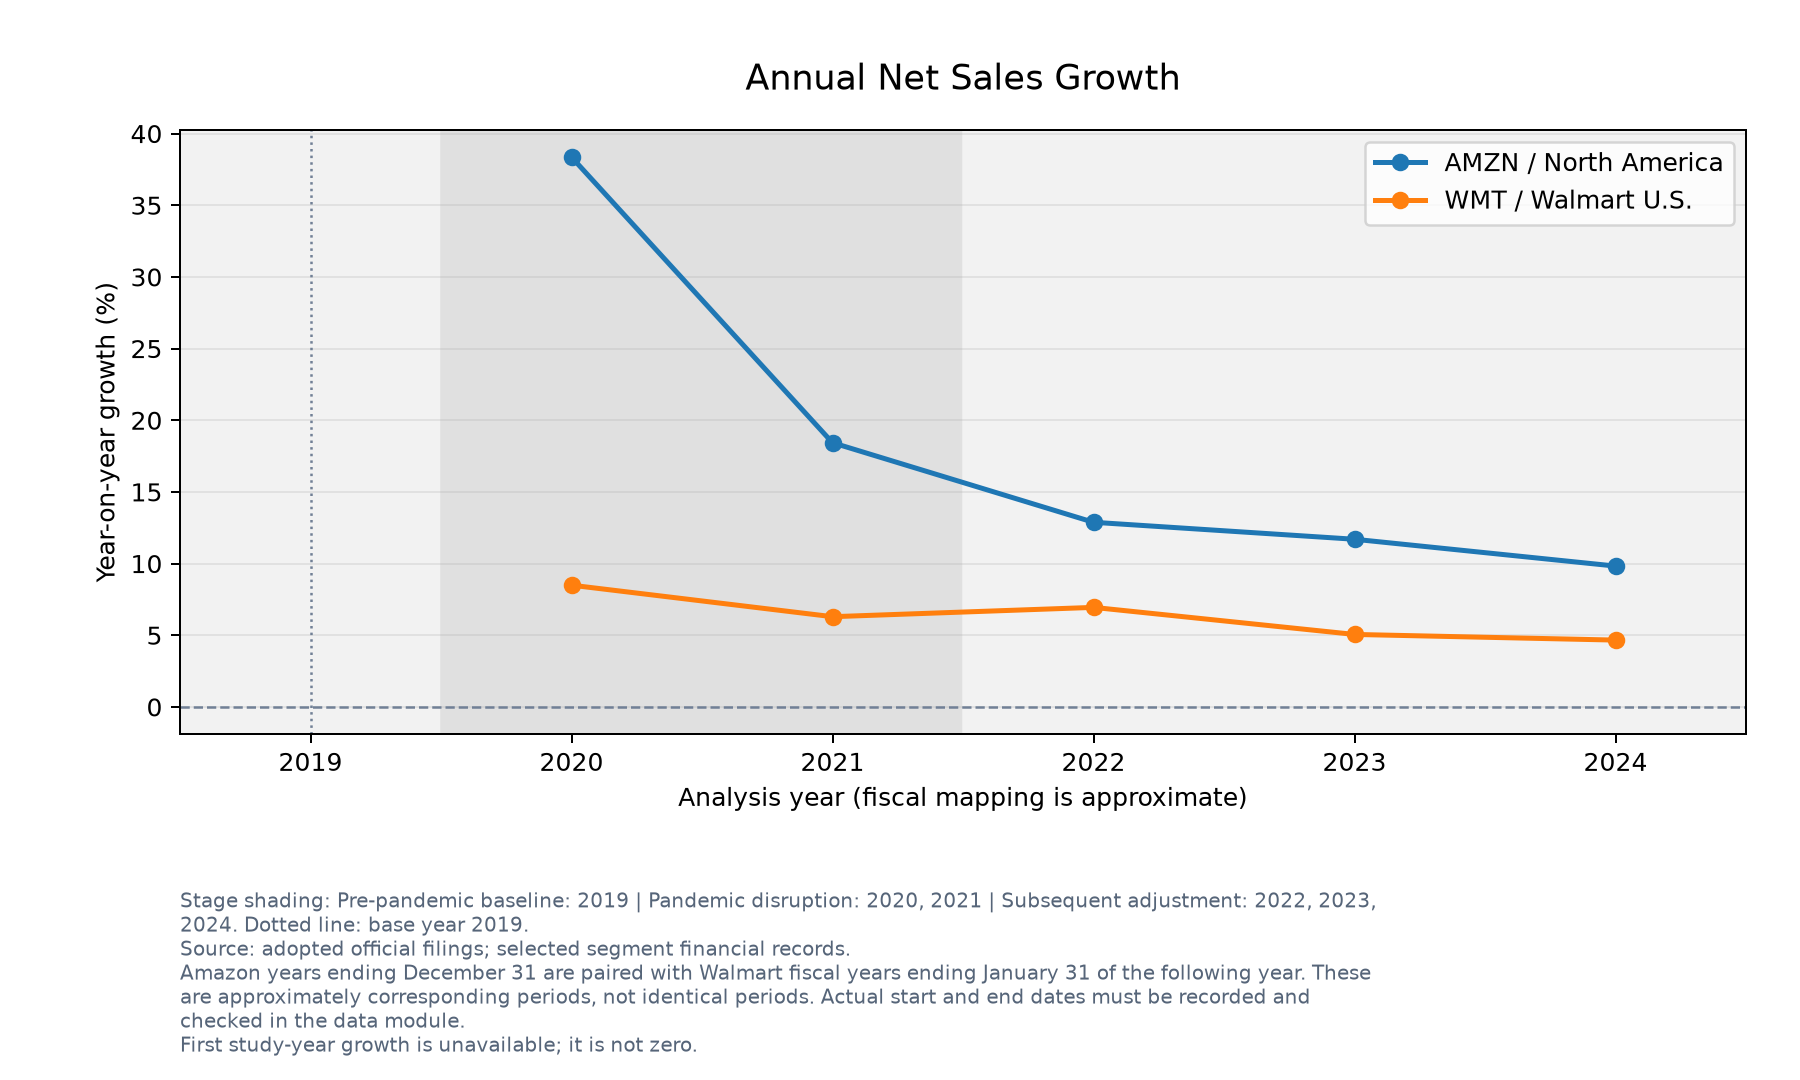

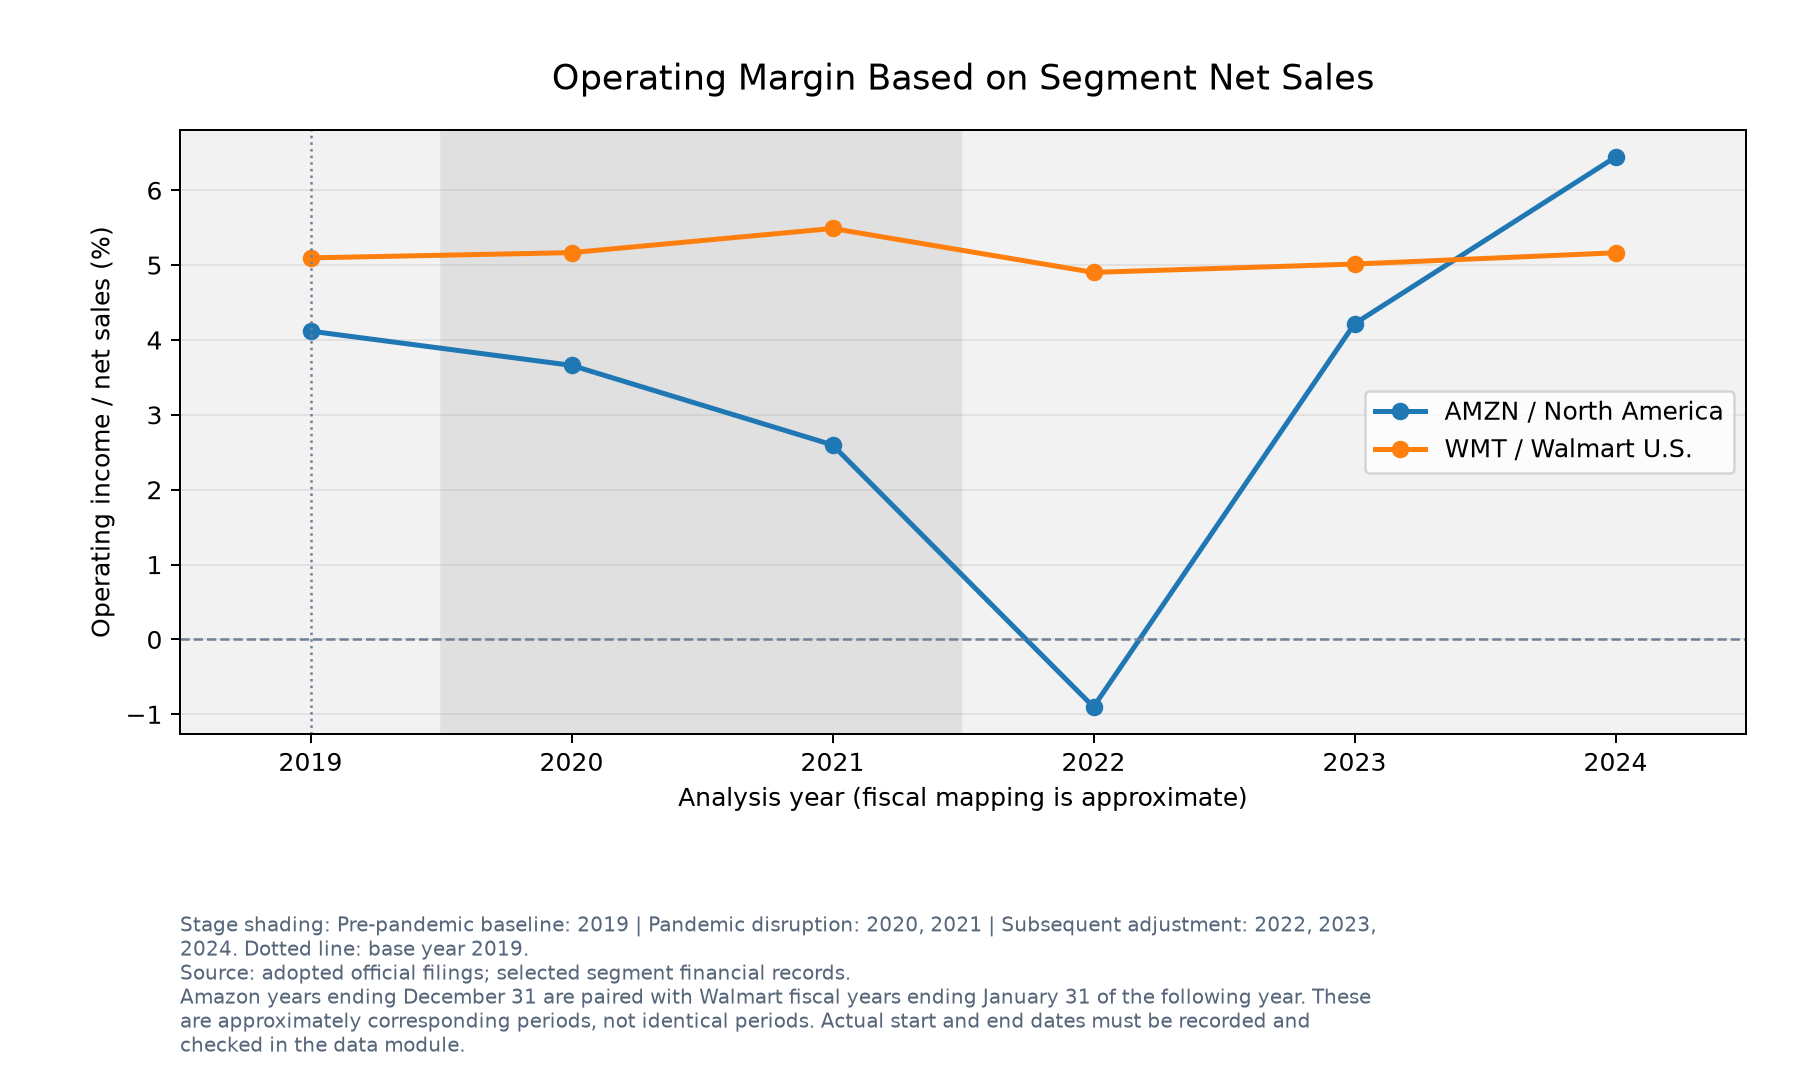

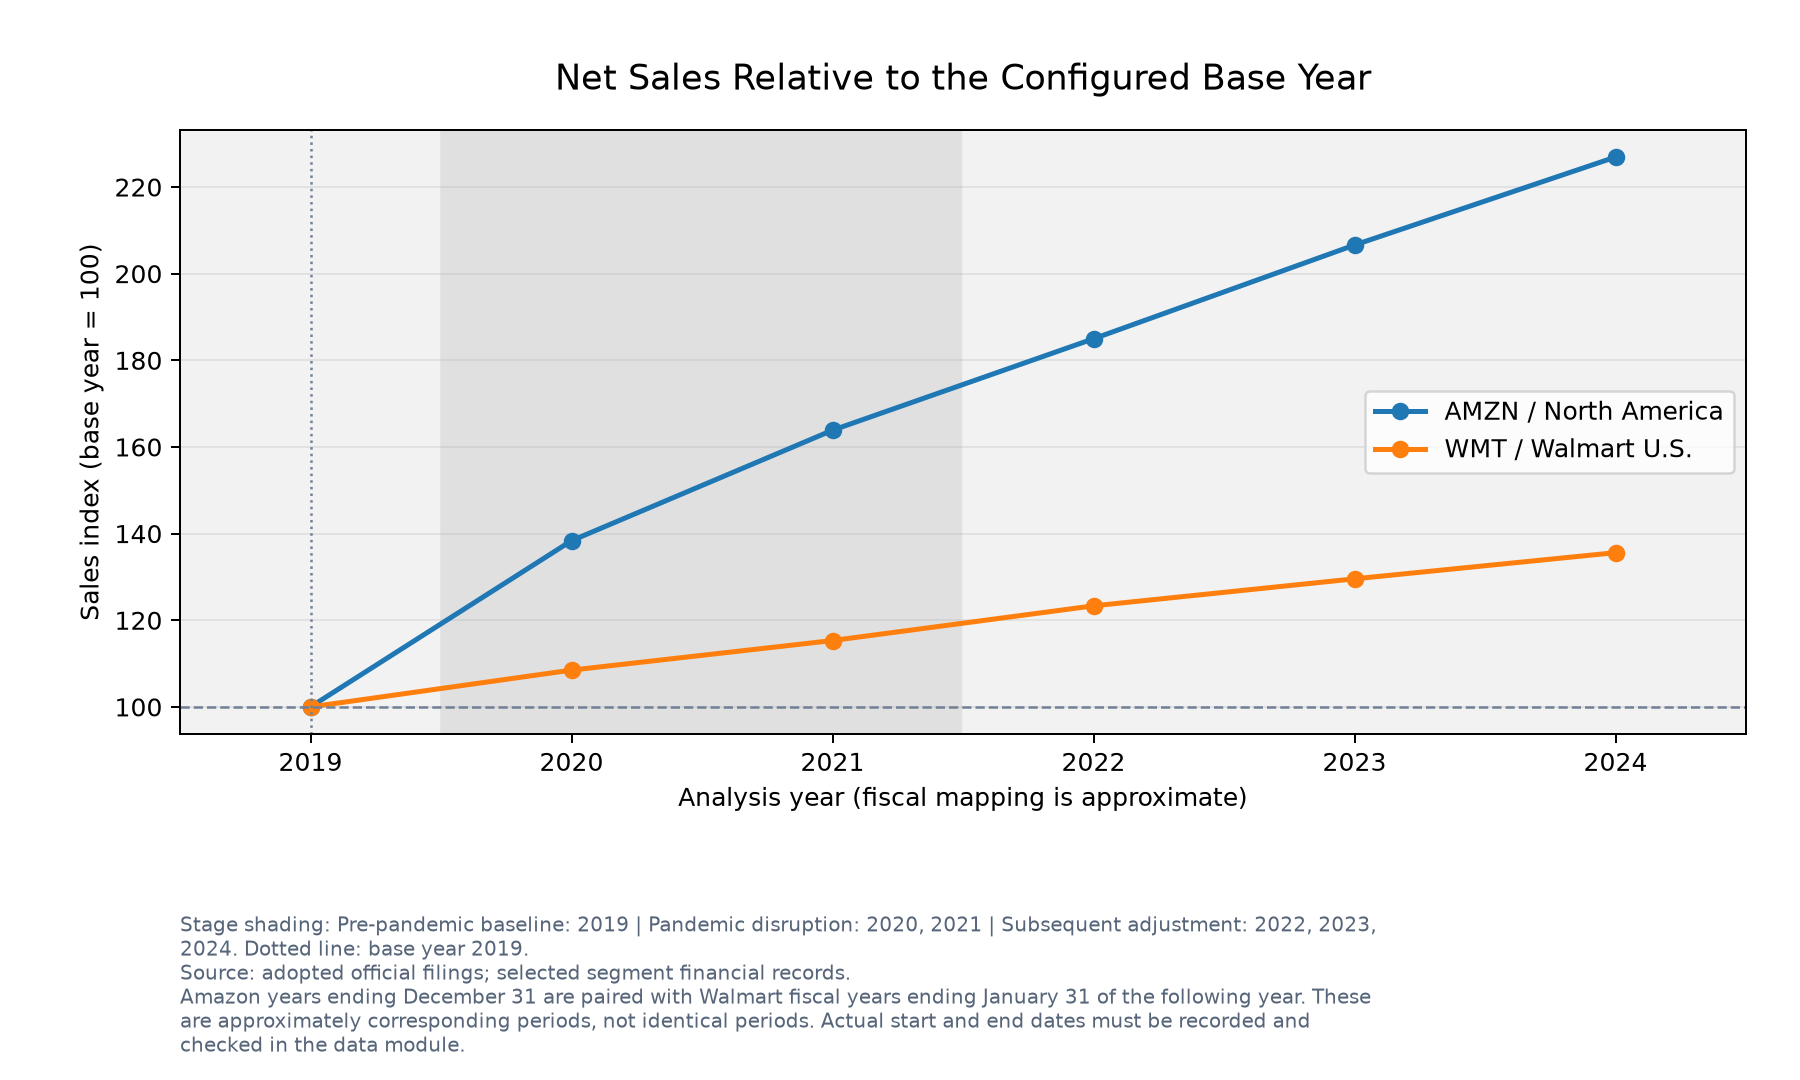

Module 04 completed. All four modules are now available.
Open research_report.html together with its figures folder.
When inputs change, rerun the workflow in module order.
Reporting reads verified metrics and does not update the database.


In [44]:
# Cell 12: Preview the Results and Complete the Workflow

preview_columns = ["company_name", "segment_name", "analysis_year", "fiscal_year"]
for metric in config.metrics:
    preview_columns.append(METRIC_SPECS[metric]["column"])
display(HTML(format_report_table(report_df[preview_columns])))

for metric in config.metrics:
    display(Image(filename=str(chart_files[metric]["png"]), width=900))

print("Module 04 completed. All four modules are now available.")
print("Open research_report.html together with its figures folder.")
print("When inputs change, rerun the workflow in module order.")
print("Reporting reads verified metrics and does not update the database.")


### 详细解释

**第 1 行｜Cell 标题是注释**

对应语句：`# Cell 12: Preview the Results and Complete the Workflow`

**语法和执行含义：** 以 # 开头，Python 不把这一行当作执行指令。Cell 编号在每个模块重新开始，英文标题说明这一格的任务。

**为什么这样写：** 你可以按编号顺序复制和运行；标题保留在代码里，但不会影响计算。

---

**第 3—5 行｜准备简洁预览表**

对应语句：`preview_columns = ["company_name", "segment_name", "analysis_year", "fiscal_year"] ⏐ for metric in config.metrics: ⏐ preview_columns.append(METRIC_SPECS[metric]["column"])`

**语法和执行含义：** 先显示对象、分析年度和财年，再逐指标追加字段名。

**为什么这样写：** Notebook 输出区只预览主要结果，完整基础字段和审计表在 HTML 中。

---

**第 6 行｜在 Notebook 展示表格**

对应语句：`display(HTML(format_report_table(report_df[preview_columns])))`

**语法和执行含义：** 先格式化 DataFrame 为 HTML，再用 HTML 包装，display 输出。

**为什么这样写：** 这是阅读显示，不会覆盖 report_df 的数值或文件。

---

**第 8—9 行｜在 Notebook 展示三张图片**

对应语句：`for metric in config.metrics: ⏐ display(Image(filename=str(chart_files[metric]["png"]), width=900))`

**语法和执行含义：** Image 的 filename 需要字符串，所以 str(Path)；width=900 限制输出区显示宽度。

**为什么这样写：** 读取已经保存的 PNG，不会再次画图或改变图片文件分辨率。

---

**第 11—12 行｜说明四模块已经完成**

对应语句：`print("Module 04 completed. All four modules are now available.") ⏐ print("Open research_report.html together with its figures folder.")`

**语法和执行含义：** 两行 print 提示完成，以及 HTML 需要同级 figures 文件夹。

**为什么这样写：** 这个模块参考 Notebook 依赖前面定义；从头运行时优先使用完整总 Notebook。

---

**第 13—14 行｜说明更新顺序与数据库边界**

对应语句：`print("When inputs change, rerun the workflow in module order.") ⏐ print("Reporting reads verified metrics and does not update the database.")`

**语法和执行含义：** 输入变更后按 Module 01→02→03→04 顺序运行。报告读取经过核对的指标，不写数据库。

**为什么这样写：** 改 CSV 不会自动更新 SQLite；改配置后不能继续使用旧签名的指标，也不能只改报告文字。

---



## 实际 DataFrame 管道

1. financial_df：从 SQLite 的 financial_records JOIN business_units 按配置查询，12 行 16 列。
2. expected_df：MetricCalculator 映射分析年度和阶段，在内存重算，12 行 22 列，仅用于核对保存结果及提供来源结构。
3. saved_df / report_metric_df：查询 metric_results 中 study_id 和当前签名的 36 行 9 列。两条 2019 同比为缺失。
4. values_by_key：把 SQL 长表整理成 (unit_id, analysis_year, metric_name) → metric_value 字典。
5. report_df：把实际 SQL 指标值放回年度表，12 行 22 列，是所有图表与报告的输入。
6. baseline_comparison_df：与各分部自身的配置基期比较，12 行 9 列，含累计销售变化和营业利润率百分点变化。
7. report_stage_df：复用第三模块阶段函数，6 行 12 列，均值与有效年数同时保留。

数据库是入口，报告不读取旧 CSV，也不修改三张 SQL 表。前三模块产生的三个 CSV 仍保留作为分析导出与核对材料。Module 04 的新 DataFrame 直接进入图表与 HTML 表，不额外重复生成 CSV。

## 保存位置与使用方法

- results/figures/sales_growth.png 与 .svg：年度销售同比，2019 不补零。
- results/figures/operating_margin.png 与 .svg：营业利润率，负值和零线保留。
- results/figures/sales_index.png 与 .svg：配置基期指数，当前为 2019=100。
- results/research_report.html：完整英文报告，包含问题、定义、自动数值描述、三张图、年度表、基期变化、阶段汇总、范围限制及可点击官方来源。
- results/report_manifest.json：报告版本、生成时间、配置快照、本次研究说明、数量和图片相对路径。

双击 HTML 用浏览器打开即可阅读，不需要运行本地网页服务。但 HTML 引用同级 figures 子目录，分享时请一起保留，或发送完整 ZIP。PNG 可预览；SVG 可供论文排版使用。图表上的阶段底纹是配置分组，竖点线是基期，横虚线是指标参考水平，不是统计区间。

## 关于复用与修改

换分析内容时，修改第一模块的研究对象、年度、财年配对和来源数据；核对 Cell 03 的 REPORT_NOTES 是否仍适用。图标题、表头和 CSS 也在 Cell 03。当前 REPORT_NOTES 明确写了 2019 和两家分部，换基期或公司时要同步修改这些文字；图中基期线、公式和自动结论的年份则由 config 自动更新。

在目前支持的三项指标范围内，更换分部名称、ID、样本年度或基期，不需要重写 ReportBuilder 与指标公式。新增全新指标则需要补充计算与展示规则，不能只改名称。来源数据必须与新研究相符。报告框架可复用，不能通过重命名把旧财务数字变成新公司的数据。

同一设置重复运行会覆盖同名报告、清单和图文件，不增加数据库行。若减少配置指标，旧的未再生成的图片文件可能仍留在 figures 中；当前报告只引用这次 chart_files 中的文件。删除过期图请先确认不需要归档。

配置或 CSV 改动后应按模块顺序重跑。报告函数若发现当前签名没有完整指标会停止，应回到第三模块完成计算保存，而不是跳过验证。写图和写 HTML/JSON 不是一个跨文件事务；中途失败时修正问题后重新执行后半段。不要把一个失败运行留下的旧 HTML 当成本次新报告。

## 检查与方法依据

前三模块检查记录见 modules_01_03_check.md 与 modules_01_03_review.json。本模块验证见 verification.txt；完整核执行版 Notebook 已在一个新 kernel 中从第一格运行到最后一格，并检查三项图文件、HTML 表、SQL 读写边界、不同基期、指标子集和新对象名称复用。原 Desktop Notebook、数据库和结果文件在检查与生成期间保持不变，完整四模块版本交付在 outputs 的项目目录。

免费来源采用第二模块已经核对的官方历史报告版本，见 ../module_02/source_notes.md。报告链接来自真实 source_url 字段，不进行新抓取，也未附完整财报 HTML。

工具参考：[Matplotlib subplots](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.subplots.html)、[Figure savefig](https://matplotlib.org/stable/api/_as_gen/matplotlib.figure.Figure.savefig.html)、[Axes axvspan](https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.axvspan.html)、[pandas to_html](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.to_html.html)、[Python html.escape](https://docs.python.org/3/library/html.html)。
